# ETL


## Import from Statsbomb

In [193]:
!pip install statsbombpy

In [194]:
from statsbombpy import sb

# get competiton id
comps = sb.competitions()
print(comps[comps["competition_international"] == True]
      .query("competition_gender == 'female'")
      [["competition_id", "season_id", "competition_name", "season_name", "competition_gender"]])

    competition_id  season_id   competition_name season_name  \
76              53        315  UEFA Women's Euro        2025   
77              53        106  UEFA Women's Euro        2022   
78              72        107  Women's World Cup        2023   
79              72         30  Women's World Cup        2019   

   competition_gender  
76             female  
77             female  
78             female  
79             female  


In [195]:
import pandas as pd

# get games
games_2019 = sb.matches(competition_id=72, season_id=30)
games_2023 = sb.matches(competition_id=72, season_id=107)
wwc_games = pd.concat([games_2019, games_2023], ignore_index=True)
print("games loaded: ", len(wwc_games))

games loaded:  116


In [71]:
wwc_games.head()

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,...,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
0,69284,2019-07-03,19:00:00.000,1,0,available,scheduled,2026-05-15T15:30:45.270304,2021-06-13T16:17:31.694,6,...,Netherlands,3016,Peter Gerhardsson,None,1959-08-22,220,Sweden,1.1.0,2,2
1,68312,2019-06-18,19:00:00.000,0,1,available,scheduled,2026-05-15T15:28:05.319873,2021-06-13T16:17:31.694,3,...,Italy,3540,Oswaldo Fumeiro Alvarez,None,1956-08-21,31,Brazil,1.1.0,2,2
2,69163,2019-06-24,19:00:00.000,1,0,available,scheduled,2026-05-15T15:23:11.912446,2021-06-13T16:17:31.694,4,...,Sweden,172,Kenneth Heiner-Møller,None,1971-01-17,61,Denmark,1.1.0,2,2
3,22964,2019-06-15,13:00:00.000,3,1,available,scheduled,2026-05-15T15:21:25.176104,2021-06-13T16:17:31.694,2,...,Netherlands,4350,Alain Djeumfa,None,1972-07-30,39,Cameroon,1.1.0,2,2
4,69301,2019-07-06,15:00:00.000,1,2,available,scheduled,2026-05-15T15:31:40.299642,2021-06-13T16:17:31.694,7,...,England,3016,Peter Gerhardsson,None,1959-08-22,220,Sweden,1.1.0,2,2


In [196]:


def get_attacking_sequences(match_id):

    events = sb.events(match_id=match_id)

    events = events.sort_values('index').copy()

    # Szekvenciák elkülönítése possession-ön belül
    group_cols = ['match_id', 'period', 'possession', 'possession_team']

    events['sequence_no'] = (
        events.groupby(group_cols)['type']
        .transform(
            lambda x: x.eq('Shot').cumsum().shift(fill_value=0)
        )
    )

    # Egyedi szekvenciaazonosító
    events['sequence_id'] = (
        events['match_id'].astype(str) + '_' +
        events['period'].astype(str) + '_' +
        events['possession'].astype(str) + '_' +
        events['possession_team'].astype(str) + '_' +
        events['sequence_no'].astype(str)
    )

    # Releváns eseménytípusok
    events = events[
        events['type'].isin(['Pass', 'Carry', 'Dribble', 'Shot'])
    ].copy()

    grouped = events.groupby('sequence_id')
    valid_mask = (grouped.size() >= 2) & (grouped['type'].last() == 'Shot')
    valid_seq_ids = valid_mask[valid_mask].index

    sequences = events[events['sequence_id'].isin(valid_seq_ids)].copy()

    return sequences

all_sequences = []
match_ids = wwc_games['match_id'].unique().tolist()

for i, match_id in enumerate(match_ids):
    try:
        seq = get_attacking_sequences(match_id)
        if not seq.empty:
            all_sequences.append(seq)
    except Exception as e:
        print(f"Hiba a {match_id} meccsnél: {e}")

df_sequences = pd.concat(all_sequences, ignore_index=True)

In [197]:
import pandas as pd

# Kinyerjük az évszámot a wwc_games 'match_date' oszlopából (vagy 'season_name' alapján)
# Biztosítjuk, hogy a match_id alapján egyértelmű legyen a párosítás
wwc_games['year'] = pd.to_datetime(wwc_games['match_date']).dt.year
match_to_year = wwc_games.set_index('match_id')['year'].to_dict()

# Új 'year' oszlop hozzáadása az attacks DataFrame-hez
df_sequences['year'] = df_sequences['match_id'].map(match_to_year)

# Ellenőrizzük az eredményt
print("Az attacks tábla első néhány sora az új 'year' oszloppal:")
print(df_sequences[['sequence_id', 'match_id', 'year']].head())
print(f"\nEgyedi évek az adathalmazban: {df_sequences['year'].dropna().unique().tolist()}")

Az attacks tábla első néhány sora az új 'year' oszloppal:
                        sequence_id  match_id  year
0  69284_1_10_Netherlands Women's_0     69284  2019
1  69284_1_10_Netherlands Women's_0     69284  2019
2  69284_1_10_Netherlands Women's_0     69284  2019
3       69284_1_30_Sweden Women's_0     69284  2019
4       69284_1_30_Sweden Women's_0     69284  2019

Egyedi évek az adathalmazban: [2019, 2023]


/tmp/ipykernel_2290/4043117326.py:9: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



In [201]:
columns_to_keep = [
    'sequence_id',
    'match_id',
    'year',
    'index',
    'id',
    'possession',
    'play_pattern',
    'possession_team',
    'type',
    'timestamp',
    'location',
    'pass_end_location',
    'carry_end_location',
    'duration',
    'pass_length',
    'pass_angle',
    'pass_height',
    'pass_cross',
    'pass_switch',
    'pass_through_ball'
    ]
df_sequences=df_sequences[columns_to_keep]

In [199]:
print(f"szekvencia: {df_sequences['sequence_id'].nunique()}, "
      f"esemény: {len(df_sequences)}, lövés {len(df_sequences[df_sequences['type']=='Shot'])}")


szekvencia: 2690, esemény: 30087, lövés 2690


## Clean df

In [202]:
df = df_sequences.drop_duplicates(subset=['id']).reset_index(drop=True)
df.head(5)

,sequence_id,match_id,year,index,id,possession,play_pattern,possession_team,type,timestamp,location,pass_end_location,carry_end_location,duration,pass_length,pass_angle,pass_height,pass_cross,pass_switch,pass_through_ball
0,69284_1_10_Netherlands Women's_0,69284,2019,99,6680e6a5-44f3-4233-ba5e-8433829303d1,10,From Free Kick,Netherlands Women's,Pass,00:02:55.758,"[86.1, 32.9]","[93.5, 23.2]",NaN,0.981424,12.20041,-0.919099,Ground Pass,NaN,NaN,NaN
1,69284_1_10_Netherlands Women's_0,69284,2019,101,09d707ef-e3f1-486f-a594-4f0dc73b2b8f,10,From Free Kick,Netherlands Women's,Carry,00:02:56.739,"[93.5, 23.2]",NaN,"[98.4, 26.7]",2.648976,NaN,NaN,NaN,NaN,NaN,NaN
2,69284_1_10_Netherlands Women's_0,69284,2019,103,2ab161a3-ab43-4a6c-967f-876e5adb2e4f,10,From Free Kick,Netherlands Women's,Shot,00:02:59.388,"[98.4, 26.7]",NaN,NaN,1.292559,NaN,NaN,NaN,NaN,NaN,NaN
3,69284_1_30_Sweden Women's_0,69284,2019,471,437aa30c-5702-4b7b-81cd-3c88cc7f11b4,30,Regular Play,Sweden Women's,Pass,00:12:27.631,"[39.2, 3.2]","[36.0, 9.2]",NaN,1.085326,6.80000,2.060754,Ground Pass,NaN,NaN,NaN
4,69284_1_30_Sweden Women's_0,69284,2019,473,4c22670f-1446-466f-848c-4048d4373522,30,Regular Play,Sweden Women's,Carry,00:12:28.716,"[36.0, 9.2]",NaN,"[34.8, 13.5]",0.996974,NaN,NaN,NaN,NaN,NaN,NaN


In [203]:
print(df.dtypes)
df.describe()

sequence_id            object
match_id                int64
year                    int64
index                   int64
id                     object
possession              int64
play_pattern           object
possession_team        object
type                   object
timestamp              object
location               object
pass_end_location      object
carry_end_location     object
duration              float64
pass_length           float64
pass_angle            float64
pass_height            object
pass_cross             object
pass_switch            object
pass_through_ball      object
dtype: object


,match_id,year,index,possession,duration,pass_length,pass_angle
count,3.008700e+04,30087.000000,30087.000000,30087.000000,30087.000000,14157.000000,14157.000000
mean,2.128169e+06,2021.164656,1882.889354,101.938811,1.581483,20.745760,-0.012550
std,1.920013e+06,1.993244,1033.541320,56.560635,1.312583,12.619829,1.552454
min,2.292100e+04,2019.000000,5.000000,2.000000,0.000000,0.400000,-3.137088
25%,2.298400e+04,2019.000000,1035.000000,55.000000,0.853363,11.600000,-1.259146
50%,3.893791e+06,2023.000000,1890.000000,101.000000,1.339500,17.555910,-0.047024
75%,3.893820e+06,2023.000000,2735.000000,147.000000,1.982744,26.947355,1.230269
max,3.906390e+06,2023.000000,4552.000000,285.000000,30.658410,94.271630,3.141593


In [204]:
pass_missing = df[df['type'] == 'Pass'][['duration','pass_length', 'pass_angle', 'pass_height', 'pass_cross', 'pass_switch', 'pass_through_ball']].isna().sum()
carry_missing = df[df['type'] == 'Carry'][['duration','carry_end_location']].isna().sum()
general_missing = df[['type', 'timestamp', 'location']].isna().sum()
print("pass", pass_missing, "carry", carry_missing, "overall", general_missing)

pass duration                 0
pass_length              0
pass_angle               0
pass_height              0
pass_cross           13274
pass_switch          13700
pass_through_ball    14030
dtype: int64 carry duration              0
carry_end_location    0
dtype: int64 overall type         0
timestamp    0
location     0
dtype: int64


In [205]:
bool_cols = ['pass_cross', 'pass_switch', 'pass_through_ball']
print(df[bool_cols].notna().sum())
df[bool_cols] = df[bool_cols].fillna(False)
df['timestamp'] = pd.to_timedelta(df['timestamp']).dt.total_seconds()

pass_cross           883
pass_switch          457
pass_through_ball    127
dtype: int64


/tmp/ipykernel_2290/799237903.py:3: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



In [206]:
import numpy as np
import pandas as pd
import ast

def parse_location(loc):
    if loc is None or (isinstance(loc, float) and pd.isna(loc)):
        return np.nan, np.nan
    if isinstance(loc, str):
        loc = ast.literal_eval(loc)
    if isinstance(loc, (list, tuple, np.ndarray)) and len(loc) >= 2:
        return loc[0], loc[1]
    return np.nan, np.nan

df['x'], df['y'] = zip(*df['location'].apply(parse_location))
df['pass_end_x'], df['pass_end_y'] = zip(*df['pass_end_location'].apply(parse_location))
df['carry_end_x'], df['carry_end_y'] = zip(*df['carry_end_location'].apply(parse_location))
df = df.drop(columns=['location', 'pass_end_location', 'carry_end_location'])

In [207]:
cols = ['x', 'y', 'pass_end_x', 'pass_end_y', 'carry_end_x', 'carry_end_y']
min_max_df = df[cols].agg(['min', 'max'])
print(min_max_df)

         x     y  pass_end_x  pass_end_y  carry_end_x  carry_end_y
min    0.9   0.1         2.0         0.1          1.5          0.4
max  120.0  80.0       120.0        79.9        119.9         79.6


In [208]:
import numpy as np
import pandas as pd

def fix_coordinates_backward_from_shot(df):
    df_fixed = df.copy()

    for seq_id, group in df_fixed.groupby('sequence_id'):
        indices = group.sort_values('index').index.tolist()
        if not indices:
            continue

        # 1. Horgonypont (Anchor): Az utolsó esemény (lövés) kezdőpontja a fix referenciapont
        last_idx = indices[-1]
        ref_x = df_fixed.loc[last_idx, 'x']
        ref_y = df_fixed.loc[last_idx, 'y']

        # 2. Visszafelé haladás az utolsó előtti eseménytől az elsőig
        for idx in reversed(indices[:-1]):
            curr_x = df_fixed.loc[idx, 'x']
            curr_y = df_fixed.loc[idx, 'y']

            # Az aktuális esemény végpontjának meghatározása
            end_x = df_fixed.loc[idx, 'pass_end_x'] if pd.notna(df_fixed.loc[idx, 'pass_end_x']) else \
                    (df_fixed.loc[idx, 'carry_end_x'] if pd.notna(df_fixed.loc[idx, 'carry_end_x']) else curr_x)
            end_y = df_fixed.loc[idx, 'pass_end_y'] if pd.notna(df_fixed.loc[idx, 'pass_end_y']) else \
                    (df_fixed.loc[idx, 'carry_end_y'] if pd.notna(df_fixed.loc[idx, 'carry_end_y']) else curr_y)

            # Távolság a rákövetkező esemény kezdőpontjától (ref_x, ref_y) eredeti és tükrözött helyzetben
            dist_orig = np.hypot(end_x - ref_x, end_y - ref_y)
            dist_flipped = np.hypot((120 - end_x) - ref_x, (80 - end_y) - ref_y)

            # 3. Csak akkor tükrözzük az egyedi eseményt, ha a tükrözött végpont érdemben közelebb áll a következő akcióhoz
            if dist_flipped < dist_orig:
                df_fixed.loc[idx, 'x'] = 120 - curr_x
                df_fixed.loc[idx, 'y'] = 80 - curr_y

                for x_col, y_col in [('pass_end_x', 'pass_end_y'), ('carry_end_x', 'carry_end_y'), ('shot_x', 'shot_y')]:
                    if x_col in df_fixed.columns and pd.notna(df_fixed.loc[idx, x_col]):
                        df_fixed.loc[idx, x_col] = 120 - df_fixed.loc[idx, x_col]
                        df_fixed.loc[idx, y_col] = 80 - df_fixed.loc[idx, y_col]

                # Frissített (módosított) kezdőpont lesz a megelőző esemény referenciája
                ref_x = 120 - curr_x
                ref_y = 80 - curr_y
            else:
                ref_x = curr_x
                ref_y = curr_y

    return df_fixed

# Alkalmazás az adathalmazra
df = fix_coordinates_backward_from_shot(df)

In [209]:
df["pass_height_num"] = (df["pass_height"] == "High Pass").astype(int)

In [210]:
magas_passz_arany = df["pass_height_num"].mean()
print(f"A magas passzok aránya: {magas_passz_arany:.2%}")

A magas passzok aránya: 10.54%


In [211]:
# vertikalitás (1 előre, -1 hátra)
df['pass_angle_cos'] = np.cos(df['pass_angle'])
#horizontális (1 jobbra, -1 balra)
df['pass_angle_sin'] = np.sin(df['pass_angle'])

In [212]:

def get_x_zone(x):
  if pd.isna(x):
    return np.nan
  if x < 40:
      return 'defensive'
  elif x < 80:
      return 'middle'
  return 'attacking'

def get_y_zone(y):
  if pd.isna(y):
    return np.nan
  if y < 26.67:
      return 'left'
  elif y > 53.33:
      return 'right'
  return 'center'



def get_pass_direction(angle):
  if pd.isna(angle):
    return np.nan
  if -np.pi / 6 <= angle <= np.pi / 6:
        return 'forward'
  elif np.abs(angle) >= 5 * np.pi / 6:
        return 'backward'
  return 'side'

In [213]:
df['x_zone'] = df['x'].apply(get_x_zone)
df['y_zone'] = df['y'].apply(get_y_zone)
df['pass_direction'] = df['pass_angle'].apply(get_pass_direction)

In [214]:
df.head()

,sequence_id,match_id,year,index,id,possession,play_pattern,possession_team,type,timestamp,duration,pass_length,pass_angle,pass_height,pass_cross,pass_switch,pass_through_ball,x,y,pass_end_x,pass_end_y,carry_end_x,carry_end_y,pass_height_num,pass_angle_cos,pass_angle_sin,x_zone,y_zone,pass_direction
0,69284_1_10_Netherlands Women's_0,69284,2019,99,6680e6a5-44f3-4233-ba5e-8433829303d1,10,From Free Kick,Netherlands Women's,Pass,175.758,0.981424,12.20041,-0.919099,Ground Pass,False,False,False,86.1,32.9,93.5,23.2,NaN,NaN,0,0.606537,-0.795055,attacking,center,side
1,69284_1_10_Netherlands Women's_0,69284,2019,101,09d707ef-e3f1-486f-a594-4f0dc73b2b8f,10,From Free Kick,Netherlands Women's,Carry,176.739,2.648976,NaN,NaN,NaN,False,False,False,93.5,23.2,NaN,NaN,98.4,26.7,0,NaN,NaN,attacking,left,NaN
2,69284_1_10_Netherlands Women's_0,69284,2019,103,2ab161a3-ab43-4a6c-967f-876e5adb2e4f,10,From Free Kick,Netherlands Women's,Shot,179.388,1.292559,NaN,NaN,NaN,False,False,False,98.4,26.7,NaN,NaN,NaN,NaN,0,NaN,NaN,attacking,center,NaN
3,69284_1_30_Sweden Women's_0,69284,2019,471,437aa30c-5702-4b7b-81cd-3c88cc7f11b4,30,Regular Play,Sweden Women's,Pass,747.631,1.085326,6.80000,2.060754,Ground Pass,False,False,False,80.8,76.8,84.0,70.8,NaN,NaN,0,-0.470588,0.882353,attacking,right,side
4,69284_1_30_Sweden Women's_0,69284,2019,473,4c22670f-1446-466f-848c-4048d4373522,30,Regular Play,Sweden Women's,Carry,748.716,0.996974,NaN,NaN,NaN,False,False,False,84.0,70.8,NaN,NaN,85.2,66.5,0,NaN,NaN,attacking,right,NaN


In [215]:
df.describe()

,match_id,year,index,possession,timestamp,duration,pass_length,pass_angle,x,y,pass_end_x,pass_end_y,carry_end_x,carry_end_y,pass_height_num,pass_angle_cos,pass_angle_sin
count,3.008700e+04,30087.000000,30087.000000,30087.000000,30087.000000,30087.000000,14157.000000,14157.000000,30087.000000,30087.000000,14157.000000,14157.000000,12565.000000,12565.000000,30087.000000,14157.000000,14157.000000
mean,2.128169e+06,2021.164656,1882.889354,101.938811,1518.529414,1.581483,20.745760,-0.012550,76.648815,39.980533,77.468320,39.794949,76.439562,39.784162,0.105428,0.206093,-0.014797
std,1.920013e+06,1.993244,1033.541320,56.560635,874.882601,1.312583,12.619829,1.552454,27.419546,22.366986,27.108816,21.248681,26.373850,21.610395,0.307109,0.647409,0.733646
min,2.292100e+04,2019.000000,5.000000,2.000000,0.276000,0.000000,0.400000,-3.137088,0.000000,0.000000,2.000000,0.100000,1.500000,0.400000,0.000000,-1.000000,-1.000000
25%,2.298400e+04,2019.000000,1035.000000,55.000000,767.499500,0.853363,11.600000,-1.259146,56.400000,21.900000,56.800000,23.000000,56.500000,21.900000,0.000000,-0.281474,-0.768725
50%,3.893791e+06,2023.000000,1890.000000,101.000000,1512.488000,1.339500,17.555910,-0.047024,80.900000,39.900000,81.400000,39.800000,80.700000,39.700000,0.000000,0.318847,-0.037012
75%,3.893820e+06,2023.000000,2735.000000,147.000000,2267.590500,1.982744,26.947355,1.230269,98.900000,58.200000,100.400000,56.800000,97.900000,57.700000,0.000000,0.820051,0.752922
max,3.906390e+06,2023.000000,4552.000000,285.000000,3479.471000,30.658410,94.271630,3.141593,120.000000,80.000000,120.000000,79.900000,119.900000,79.600000,1.000000,1.000000,1.000000


In [216]:

df.to_csv('attacking_sequences.csv', index=False)

# Load csv

In [1]:
import pandas as pd

# URL to the raw CSV on GitHub
github_url = 'https://raw.githubusercontent.com/lovajujo/evolution-of-attacking-plays-in-women-s-football/refs/heads/main/attacking_sequences.csv'
try:
    df = pd.read_csv(github_url)
    print("Data loaded successfully from GitHub!")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
except Exception as e:
    print(f"Error loading from GitHub: {e}\nPlease make sure the repository and file path are public and correct.")

Data loaded successfully from GitHub!
Rows: 30087, Columns: 27


In [ ]:
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')
path='/content/drive/Othercomputers/Saját laptop/Jujo/tf elemzes msc/3/szakdoga/attacking_sequences.csv'
df = pd.read_csv(path)
df.head()

In [4]:
df.head()

,sequence_id,match_id,year,index,id,possession,type,timestamp,duration,pass_length,pass_angle,pass_height,pass_cross,pass_switch,pass_through_ball,x,y,pass_end_x,pass_end_y,carry_end_x,carry_end_y,pass_height_num,pass_angle_cos,pass_angle_sin,x_zone,y_zone,pass_direction
0,69284_1_10_0,69284,2019,99,6680e6a5-44f3-4233-ba5e-8433829303d1,10,Pass,175.758,0.981424,12.20041,-0.919099,Ground Pass,False,False,False,86.1,32.9,93.5,23.2,NaN,NaN,0,0.606537,-0.795055,attacking,center,side
1,69284_1_10_0,69284,2019,101,09d707ef-e3f1-486f-a594-4f0dc73b2b8f,10,Carry,176.739,2.648976,NaN,NaN,NaN,False,False,False,93.5,23.2,NaN,NaN,98.4,26.7,0,NaN,NaN,attacking,left,NaN
2,69284_1_10_0,69284,2019,103,2ab161a3-ab43-4a6c-967f-876e5adb2e4f,10,Shot,179.388,1.292559,NaN,NaN,NaN,False,False,False,98.4,26.7,NaN,NaN,NaN,NaN,0,NaN,NaN,attacking,center,NaN
3,69284_1_30_0,69284,2019,471,437aa30c-5702-4b7b-81cd-3c88cc7f11b4,30,Pass,747.631,1.085326,6.80000,2.060754,Ground Pass,False,False,False,80.8,76.8,84.0,70.8,NaN,NaN,0,-0.470588,0.882353,defensive,left,side
4,69284_1_30_0,69284,2019,473,4c22670f-1446-466f-848c-4048d4373522,30,Carry,748.716,0.996974,NaN,NaN,NaN,False,False,False,84.0,70.8,NaN,NaN,85.2,66.5,0,NaN,NaN,defensive,left,NaN


In [5]:
pd.set_option('display.max_columns', None)
df.columns

Index(['sequence_id', 'match_id', 'year', 'index', 'id', 'possession', 'type',
       'timestamp', 'duration', 'pass_length', 'pass_angle', 'pass_height',
       'pass_cross', 'pass_switch', 'pass_through_ball', 'x', 'y',
       'pass_end_x', 'pass_end_y', 'carry_end_x', 'carry_end_y',
       'pass_height_num', 'pass_angle_cos', 'pass_angle_sin', 'x_zone',
       'y_zone', 'pass_direction'],
      dtype='object')

# Tokenizálás

## chains

In [57]:
df_to_tokens=df.copy()

In [58]:
df_to_tokens['long_pass'] = (df_to_tokens['pass_length'] > 35).astype(int)
df_to_tokens['pass_direction_bin'] = df_to_tokens['pass_direction'].replace({'forward': 'progressive',
                                                         'backward': 'non progressive',
                                                         'side':'non progressive'})
df_to_tokens['y_zone_bin']=df_to_tokens['y_zone'].replace({'left': 'side', 'right': 'side'})

In [59]:
import itertools

x_vals = ['defensive', 'middle', 'attacking']
y_vals = ['side', 'center']
l_vals = [0, 1]
d_vals = ['progressive', 'non progressive']

def make_label(x, y, l, d):
    return f"{x}_{y}_{'long' if l else 'short'}_{d}"

all_labels = [make_label(*c) for c in itertools.product(x_vals, y_vals, l_vals, d_vals)]
assert len(all_labels) == 24

is_pass = df_to_tokens['pass_length'].notna()

df_to_tokens['pass_cluster'] = pd.NA
df_to_tokens.loc[is_pass, 'pass_cluster'] = (
    df_to_tokens.loc[is_pass, 'x_zone'].astype(str) + '_' +
    df_to_tokens.loc[is_pass, 'y_zone_bin'].astype(str) + '_' +
    df_to_tokens.loc[is_pass, 'long_pass'].map({0: 'short', 1: 'long'}) + '_' +
    df_to_tokens.loc[is_pass, 'pass_direction_bin'].astype(str)
)

# ellenőrzés: nem várt értékek
unexpected = set(df_to_tokens['pass_cluster'].dropna().unique()) - set(all_labels)
print("Váratlan címkék:", unexpected)   # üresnek kell lennie

# 4) one-hot: 24 oszlop (a nem-passz sorokban csupa 0)
df_to_tokens['pass_cluster'] = pd.Categorical(df_to_tokens['pass_cluster'], categories=all_labels)
pc_dummies = pd.get_dummies(df_to_tokens['pass_cluster'], prefix='pc', dtype=int)
df_to_tokens = pd.concat([df_to_tokens, pc_dummies], axis=1)

pc_cols = list(pc_dummies.columns)   # 24 oszlop
print(len(pc_cols), df_to_tokens[pc_cols].sum().sort_values(ascending=False))

Váratlan címkék: set()
24 pc_attacking_side_short_non progressive      3324
pc_middle_side_short_non progressive         2552
pc_middle_center_short_non progressive       1393
pc_attacking_center_short_non progressive    1017
pc_middle_side_short_progressive              877
pc_defensive_side_short_non progressive       822
pc_attacking_side_long_non progressive        717
pc_defensive_center_short_non progressive     632
pc_attacking_side_short_progressive           474
pc_defensive_side_short_progressive           384
pc_middle_center_short_progressive            335
pc_middle_side_long_non progressive           287
pc_defensive_center_short_progressive         192
pc_middle_side_long_progressive               190
pc_middle_center_long_non progressive         181
pc_attacking_center_short_progressive         180
pc_defensive_center_long_progressive          162
pc_defensive_side_long_progressive            156
pc_middle_center_long_progressive              89
pc_defensive_center_long

In [60]:
import numpy as np
import pandas as pd
import itertools

# --- 1) carry jellemzők -------------------------------------------------
is_carry = df['type'] == 'Carry'

dx = df_to_tokens['carry_end_x'] - df_to_tokens['x']
dy = df_to_tokens['carry_end_y'] - df_to_tokens['y']
df_to_tokens['carry_length'] = np.where(is_carry, np.hypot(dx, dy), np.nan)

# a hossz-küszöböt a carry-k eloszlásából érdemes választani, nem a passzokéból
print(df_to_tokens.loc[is_carry, 'carry_length'].describe(percentiles=[.5, .75, .9]))

LONG_CARRY = 10     # yard; ~a 75. percentilis körül érdemes lennie
PROG_DX    = 5      # yard előre = progresszív (a passzoknál használt logikához igazítsd)

df_to_tokens['long_carry']  = np.where(is_carry, (df_to_tokens['carry_length'] > LONG_CARRY).astype(int), np.nan)
df_to_tokens['carry_direction_bin'] = np.where(is_carry,
                                     np.where(dx >= PROG_DX, 'progressive', 'non progressive'),
                                     None)

# --- 2) carry_cluster címke ---------------------------------------------
x_vals = ['defensive', 'middle', 'attacking']
y_vals = ['side', 'center']
l_vals = ['short', 'long']
d_vals = ['progressive', 'non progressive']
carry_labels = ['_'.join(c) for c in itertools.product(x_vals, y_vals, l_vals, d_vals)]
assert len(carry_labels) == 24

df_to_tokens['carry_cluster'] = pd.NA
df_to_tokens.loc[is_carry, 'carry_cluster'] = (
    df_to_tokens.loc[is_carry, 'x_zone'].astype(str) + '_' +
    df_to_tokens.loc[is_carry, 'y_zone_bin'].astype(str) + '_' +
    df_to_tokens.loc[is_carry, 'long_carry'].map({0: 'short', 1: 'long'}) + '_' +
    df_to_tokens.loc[is_carry, 'carry_direction_bin']
)
print("Váratlan:", set(df_to_tokens['carry_cluster'].dropna()) - set(carry_labels))

df_to_tokens['carry_cluster'] = pd.Categorical(df_to_tokens['carry_cluster'], categories=carry_labels)
cc_dummies = pd.get_dummies(df_to_tokens['carry_cluster'], prefix='cc', dtype=int)
df_to_tokens = pd.concat([df_to_tokens, cc_dummies], axis=1)
cc_cols = list(cc_dummies.columns)
print(len(cc_cols), df_to_tokens[cc_cols].sum().sort_values(ascending=False))

count    12565.000000
mean         6.153220
std          7.050313
min          0.000000
50%          3.920459
75%          8.263776
90%         14.979453
max         72.599862
Name: carry_length, dtype: float64
Váratlan: set()
24 cc_attacking_side_short_non progressive      2706
cc_middle_side_short_non progressive         2267
cc_attacking_center_short_non progressive    1330
cc_middle_center_short_non progressive       1194
cc_defensive_side_short_non progressive       854
cc_defensive_center_short_non progressive     610
cc_middle_side_long_progressive               575
cc_attacking_side_long_progressive            545
cc_attacking_side_short_progressive           354
cc_middle_side_short_progressive              297
cc_middle_center_long_progressive             297
cc_attacking_side_long_non progressive        211
cc_middle_center_short_progressive            166
cc_middle_side_long_non progressive           162
cc_attacking_center_short_progressive         153
cc_defensive_side_lo

In [93]:
import pandas as pd
import numpy as np

df_to_tokens = df_to_tokens.sort_values(['sequence_id', 'index']).copy()

# --- 1) token eseményenként -------------------------------------------------
def make_token(r):
    t = r['type']
    if t == 'Pass':
        return None if pd.isna(r['pass_cluster']) else 'pc_' + str(r['pass_cluster']).replace(' ', '-')   # szóköz nélkül!
    if t == 'Carry':
        return None if pd.isna(r['carry_cluster']) else 'cc_' + str(r['carry_cluster']).replace(' ', '-')
    if t == 'Dribble':
        return 'dribble'
    if t == 'Shot':
        return 'shot'
    return None   # Ball Receipt, Pressure, Duel stb. kihagyva

df_to_tokens['token'] = df_to_tokens.apply(make_token, axis=1)
ev = df_to_tokens[df_to_tokens['token'].notna()]

# --- 2) láncok szekvenciánként ---------------------------------------------
def build_chain(tokens, last_n=15, drop_shot=True, dedupe=True):
    toks = list(tokens)
    if drop_shot and toks and toks[-1] == 'shot':
        toks = toks[:-1]                       # minden lánc lövéssel végződik
    return toks[-last_n:]                      # a befejezés felőli utolsó N token

seqs = (ev.groupby('sequence_id')['token']
          .apply(build_chain)
          .rename('chain').to_frame())
#seqs = seqs[seqs['chain'].str.len() >= 2]      # túl rövid láncok kiszűrése
seqs['chain_str'] = seqs['chain'].apply(' '.join)

# metaadat (vb és meccs) a későbbi összehasonlításhoz
meta = df_to_tokens.groupby('sequence_id')[['match_id', 'year']].first()
sequences = seqs.join(meta)
print(sequences['chain_str'].head())
print(sequences['chain'].str.len().describe())

sequence_id
22921_1_17_0    cc_middle_side_short_non-progressive pc_middle...
22921_1_24_0    pc_attacking_side_short_progressive cc_attacki...
22921_1_31_0    pc_attacking_side_long_non-progressive pc_atta...
22921_1_46_0               pc_attacking_side_long_non-progressive
22921_1_46_1    pc_attacking_center_short_non-progressive cc_m...
Name: chain_str, dtype: object
count    2690.000000
mean        7.678810
std         5.383559
min         1.000000
25%         2.000000
50%         7.000000
75%        14.000000
max        15.000000
Name: chain, dtype: float64


## td-idf + kmeans

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency

vec = TfidfVectorizer(token_pattern=r"\S+", lowercase=False,
                      ngram_range=(1, 3), min_df=15, sublinear_tf=True)
X = vec.fit_transform(sequences['chain_str'])
terms = np.array(vec.get_feature_names_out())
print("TF-IDF:", X.shape)

N_COMP = 20
lsi = make_pipeline(TruncatedSVD(n_components=N_COMP, random_state=0),
                    Normalizer(copy=False))
Z = lsi.fit_transform(X)
print("LSI magyarázott variancia:", lsi[0].explained_variance_ratio_.sum().round(3))

TF-IDF: (2690, 419)
LSI magyarázott variancia: 0.457


     k   inertia  silhouette  ARI_mean  ARI_sd
0    4  1500.679       0.209     0.956   0.079
1    5  1410.806       0.211     0.823   0.103
2    6  1322.800       0.229     0.754   0.071
3    7  1253.235       0.240     0.724   0.113
4    8  1189.801       0.247     0.835   0.077
5    9  1133.526       0.261     0.767   0.084
6   10  1089.912       0.266     0.708   0.062
7   11  1057.650       0.264     0.730   0.050
8   12  1011.803       0.275     0.759   0.049
9   13   971.896       0.280     0.779   0.051
10  14   937.745       0.287     0.742   0.039
11  15   901.059       0.292     0.792   0.046


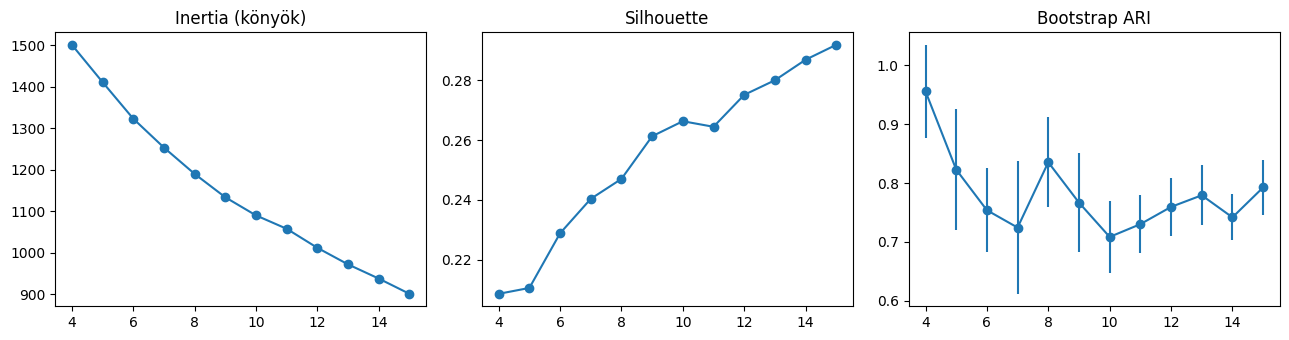

In [95]:
def stability(Z, k, n_boot=30, frac=0.8, seed=0):
    rng = np.random.default_rng(seed)
    base = KMeans(k, n_init=10, random_state=0).fit(Z)
    base_lab = base.labels_
    aris = []
    for _ in range(n_boot):
        idx = rng.choice(len(Z), int(frac * len(Z)), replace=False)
        km = KMeans(k, n_init=5, random_state=int(rng.integers(1e6))).fit(Z[idx])
        aris.append(adjusted_rand_score(base_lab, km.predict(Z)))
    return np.mean(aris), np.std(aris)

rows = []
for k in range(4, 16):
    km = KMeans(k, n_init=10, random_state=0).fit(Z)
    sil = silhouette_score(Z, km.labels_)
    ari_m, ari_s = stability(Z, k)
    rows.append((k, km.inertia_, sil, ari_m, ari_s))
sel = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette', 'ARI_mean', 'ARI_sd'])
print(sel.round(3))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(sel.k, sel.inertia, 'o-');    ax[0].set_title('Inertia (könyök)')
ax[1].plot(sel.k, sel.silhouette, 'o-'); ax[1].set_title('Silhouette')
ax[2].errorbar(sel.k, sel.ARI_mean, sel.ARI_sd, fmt='o-'); ax[2].set_title('Bootstrap ARI')
plt.tight_layout(); plt.show()


In [100]:
K = 4                                     # a fenti táblázat alapján állítsd
km = KMeans(K, n_init=20, random_state=0).fit(Z)
sequences['cluster'] = km.labels_

In [101]:

for c in range(K):
    mask = (sequences['cluster'] == c).values
    cent = np.asarray(X[mask].mean(axis=0)).ravel()
    lift = cent - global_mean                         # mi jellemzőbb itt, mint átlagosan
    top = terms[np.argsort(lift)[::-1][:8]]

    # reprezentatív láncok: a centroidhoz legközelebbi 3
    d = ((Z[mask] - km.cluster_centers_[c]) ** 2).sum(axis=1)
    rep = sequences.loc[mask, 'chain_str'].iloc[np.argsort(d)[:3]]

    print(f"\n=== Klaszter {c} (n={mask.sum()}, "
          f"átlag lánchossz={sequences.loc[mask,'chain'].str.len().mean():.1f}) ===")
    print("Jellemző n-gramok:", ', '.join(top))
    for r in rep:
        print("  példa:", r)


=== Klaszter 0 (n=465, átlag lánchossz=7.1) ===
Jellemző n-gramok: cc_attacking_center_short_non-progressive, pc_attacking_center_short_non-progressive, cc_attacking_center_short_non-progressive pc_attacking_center_short_non-progressive, pc_attacking_center_short_non-progressive cc_attacking_center_short_non-progressive, cc_attacking_center_short_non-progressive pc_attacking_center_short_non-progressive cc_attacking_center_short_non-progressive, pc_attacking_side_short_non-progressive cc_attacking_center_short_non-progressive, pc_attacking_center_short_non-progressive cc_attacking_center_short_non-progressive pc_attacking_center_short_non-progressive, pc_attacking_center_short_progressive
  példa: cc_attacking_center_short_non-progressive pc_attacking_center_short_non-progressive
  példa: pc_middle_side_short_non-progressive cc_attacking_center_short_non-progressive pc_attacking_center_short_non-progressive cc_attacking_center_short_progressive
  példa: pc_middle_center_short_non-prog

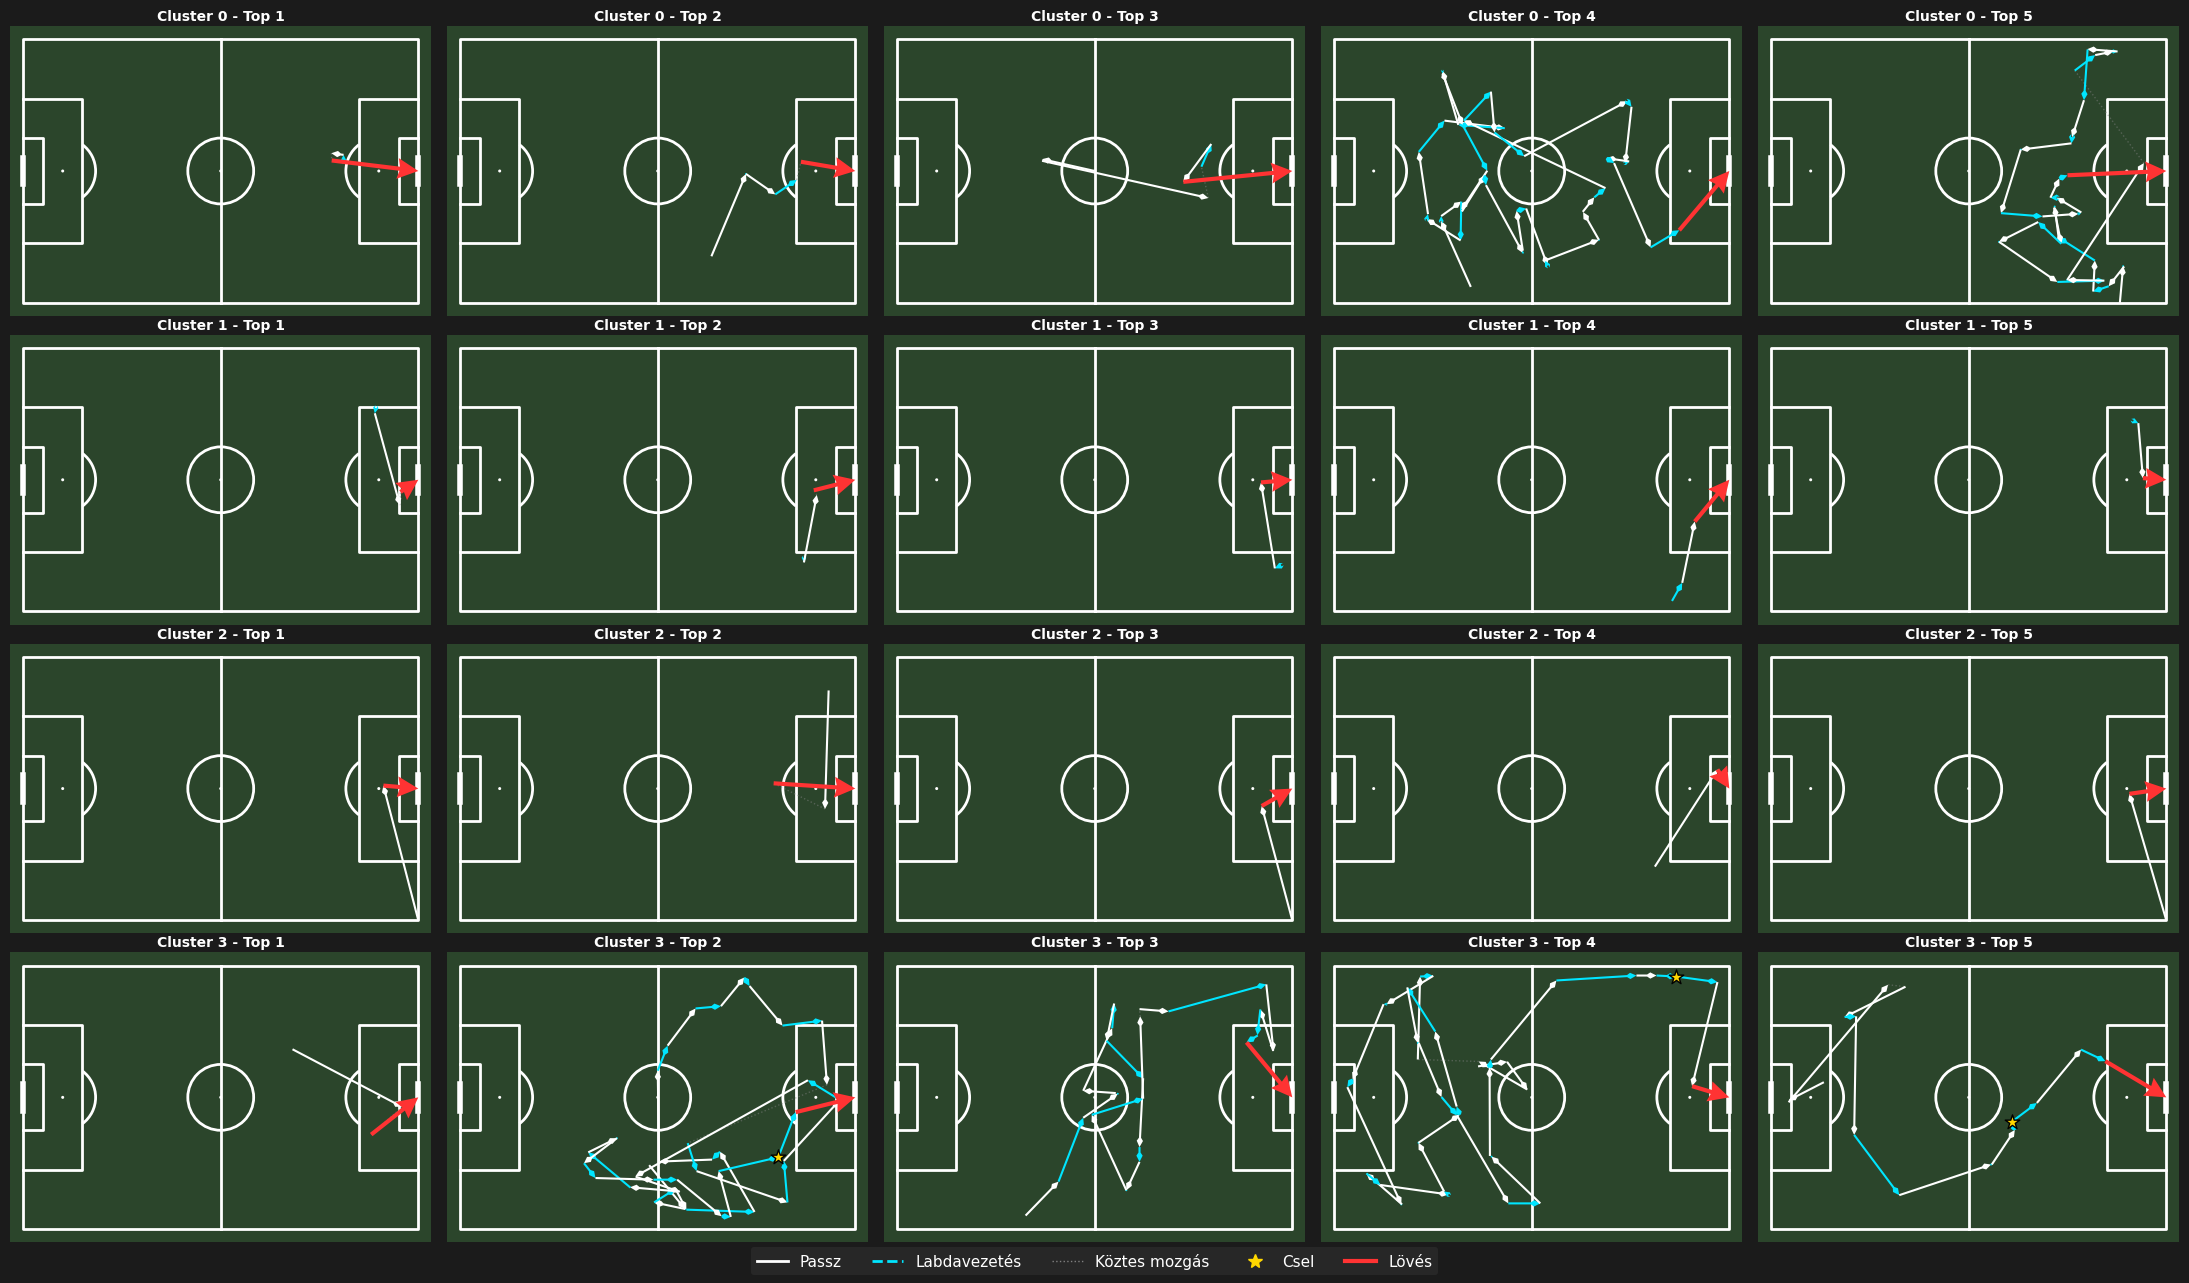

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances

try:
    from mplsoccer import Pitch
except ImportError:
    !pip install mplsoccer
    from mplsoccer import Pitch

# 1. 7 klaszter és a reprezentatív szekvenciák (top 5/klaszter) meghatározása
unique_clusters = sorted(sequences['cluster'].dropna().unique())
k = len(unique_clusters)
top_n = 5

# A távolságokat a betanításhoz használt 'Z' (LSI) térben mérjük
distances = euclidean_distances(Z, km.cluster_centers_)

# 2. Pályák inicializálása
pitch = Pitch(pitch_type='statsbomb', pitch_color='#2b452b', line_color='white')
fig, axes = pitch.draw(nrows=k, ncols=top_n, figsize=(22, 3.2 * k))
fig.patch.set_facecolor('#1b1b1b')

# 3. Klaszterenként a legközelebbi 5 szekvencia kirajzolása
for row_idx, cluster_id in enumerate(unique_clusters):
    cluster_indices = np.where(sequences['cluster'] == cluster_id)[0]

    # Adott klaszteren belüli top 5 legközelebbi elem kiválasztása
    top5_local = np.argsort(distances[cluster_indices, cluster_id])[:top_n]
    # JAVÍTÁS: Mivel a 'sequence_id' az index, .index-szel kérjük le az értékeket
    top5_seq_ids = sequences.index[cluster_indices[top5_local]].values

    for sample_idx, seq_id in enumerate(top5_seq_ids):
        ax = axes[row_idx, sample_idx] if k > 1 else axes[sample_idx]
        ax.set_title(f'Cluster {cluster_id} - Top {sample_idx+1}', color='white', fontsize=10, fontweight='bold', pad=4)

        seq_events = df[df['sequence_id'] == seq_id].sort_values('index')

        prev_end_x, prev_end_y = None, None
        for _, event in seq_events.iterrows():
            curr_x, curr_y = event['x'], event['y']

            # Koordinátahézagok áthidalása szürke pontozott vonallal
            if prev_end_x is not None and (prev_end_x != curr_x or prev_end_y != curr_y):
                ax.plot([prev_end_x, curr_x], [prev_end_y, curr_y], color='gray', linestyle=':', linewidth=1, alpha=0.5, zorder=2)

            # Passz
            if pd.notna(event.get('pass_end_x')) and pd.notna(event.get('pass_end_y')):
                pitch.arrows(event['x'], event['y'], event['pass_end_x'], event['pass_end_y'], ax=ax, color='white', width=1.5, headwidth=3, headlength=3, zorder=3)
                prev_end_x, prev_end_y = event['pass_end_x'], event['pass_end_y']
            # Labdavezetés
            elif pd.notna(event.get('carry_end_x')) and pd.notna(event.get('carry_end_y')):
                pitch.arrows(event['x'], event['y'], event['carry_end_x'], event['carry_end_y'], ax=ax, color='#00e5ff', width=1.5, headwidth=3, headlength=3, linestyle='--', zorder=3)
                prev_end_x, prev_end_y = event['carry_end_x'], event['carry_end_y']
            else:
                prev_end_x, prev_end_y = curr_x, curr_y

            # Csel
            if event.get('type') == 'Dribble' or event.get('dribble_ratio', 0) > 0:
                ax.scatter(event['x'], event['y'], marker='*', color='gold', s=120, edgecolors='black', zorder=5)
            # Lövés
            if event.get('type') == 'Shot' or pd.notna(event.get('shot_x')):
                shot_x = event.get('shot_x', event['x'])
                shot_y = event.get('shot_y', event['y'])
                pitch.arrows(shot_x, shot_y, 120, 40, ax=ax, color='#ff3333', width=3, headwidth=5, headlength=5, zorder=6)

# 4. Jelmagyarázat
legend_elements = [
    plt.Line2D([0], [0], color='white', lw=2, label='Passz'),
    plt.Line2D([0], [0], color='#00e5ff', lw=2, linestyle='--', label='Labdavezetés'),
    plt.Line2D([0], [0], color='gray', lw=1, linestyle=':', label='Köztes mozgás'),
    plt.Line2D([0], [0], marker='*', color='gold', label='Csel', markerfacecolor='gold', markersize=10, linestyle='None'),
    plt.Line2D([0], [0], color='#ff3333', lw=3, label='Lövés')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=5, fontsize=11, frameon=True, facecolor='#2b2b2b', edgecolor='none', labelcolor='white')

plt.tight_layout()
plt.subplots_adjust(bottom=0.03)
plt.show()

## Levenshtein + hierarchikus

In [108]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering

try:
    import Levenshtein
except ImportError:
    !pip install python-Levenshtein
    import Levenshtein

# 1. Események leképezése egyedi karakterekre a gyors Levenshtein-számításhoz
unique_tokens = sorted(list(set([token for chain in sequences['chain'] for token in chain])))
token_to_char = {token: chr(i + 33) for i, token in enumerate(unique_tokens)}

# Eseményláncok átalakítása karakterláncokká (stringekké)
char_sequences = [
    "".join([token_to_char[t] for t in chain])
    for chain in sequences['chain']
]

# 2. Levenshtein távolságmátrix előállítása
n = len(char_sequences)
dist_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(i + 1, n):
        d = Levenshtein.distance(char_sequences[i], char_sequences[j])
        dist_matrix[i, j] = d
        dist_matrix[j, i] = d

# 3. Hierarchikus (Agglomeratív) klaszterezés precomputed távolságmátrixszal
K = 12
hc = AgglomerativeClustering(n_clusters=K, metric='precomputed', linkage='average')
sequences['cluster_hc'] = hc.fit_predict(dist_matrix)

# 4. Klaszterek kiértékelése és a medoidok (reprezentatív láncok) meghatározása
for c in range(K):
    mask = (sequences['cluster_hc'] == c).values
    sub_indices = np.where(mask)[0]

    if len(sub_indices) > 0:
        # Medoid: a klaszteren belüli legkisebb átlagos távolságú elem
        sub_dist = dist_matrix[np.ix_(sub_indices, sub_indices)]
        medoid_local_idx = np.argmin(sub_dist.sum(axis=1))
        medoid_global_idx = sub_indices[medoid_local_idx]
        # JAVÍTÁS: .loc helyett .iloc használata, mivel a sequences indexe szöveges (sequence_id)
        rep_chain = sequences['chain_str'].iloc[medoid_global_idx]
    else:
        rep_chain = "N/A"

    avg_len = sequences.loc[mask, 'chain'].str.len().mean()
    print(f"\n=== HC Klaszter {c} (n={mask.sum()}, átlaghossz={avg_len:.1f}) ===")
    print("  Reprezentatív lánc (Medoid):", rep_chain)


=== HC Klaszter 0 (n=5, átlaghossz=15.0) ===
  Reprezentatív lánc (Medoid): pc_middle_side_short_non-progressive cc_defensive_side_long_non-progressive pc_middle_side_short_progressive pc_middle_center_short_progressive cc_middle_center_long_non-progressive dribble cc_middle_side_long_non-progressive pc_attacking_side_short_progressive cc_attacking_side_long_non-progressive pc_attacking_side_short_non-progressive cc_defensive_center_long_progressive pc_defensive_center_long_progressive pc_middle_side_long_non-progressive pc_attacking_center_short_non-progressive pc_attacking_center_short_non-progressive

=== HC Klaszter 1 (n=95, átlaghossz=14.6) ===
  Reprezentatív lánc (Medoid): pc_defensive_center_short_non-progressive cc_defensive_side_short_non-progressive pc_defensive_side_short_non-progressive cc_defensive_side_short_non-progressive pc_defensive_side_short_non-progressive cc_defensive_side_short_non-progressive pc_defensive_side_long_progressive cc_middle_side_short_non-progress

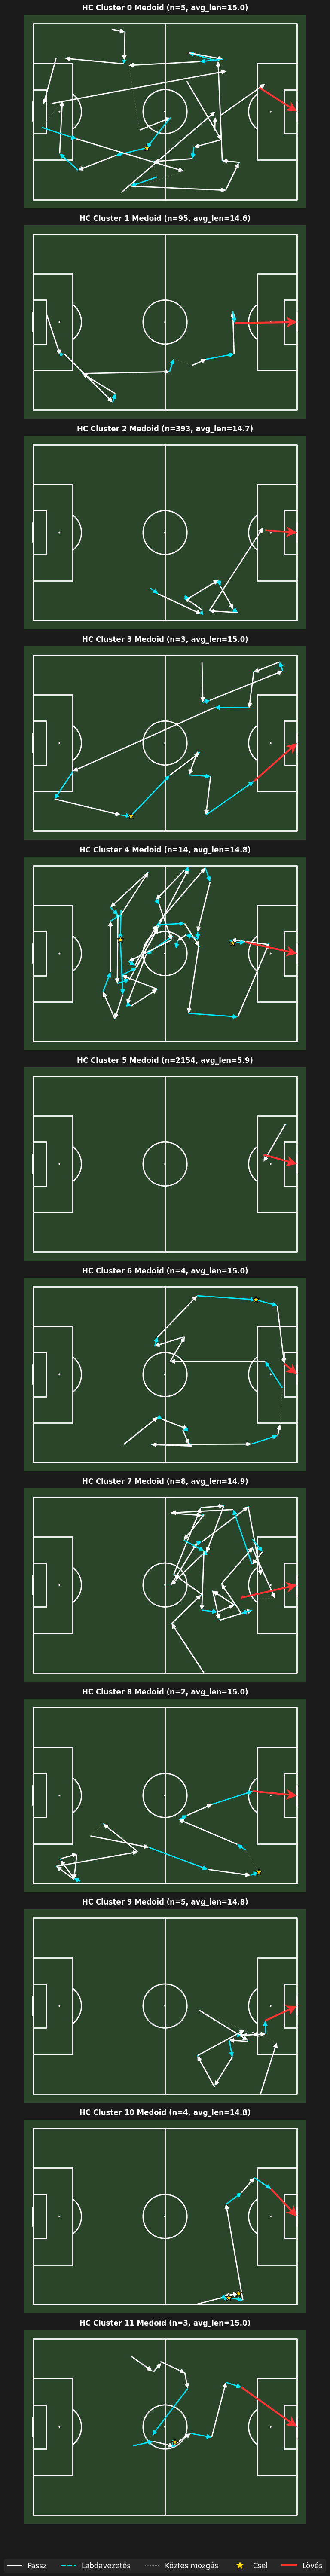

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from mplsoccer import Pitch
except ImportError:
    !pip install mplsoccer
    from mplsoccer import Pitch

# 1. Klaszterszám és medoidok összegyűjtése
unique_hc_clusters = sorted(sequences['cluster_hc'].dropna().unique())
num_hc_clusters = len(unique_hc_clusters)

medoid_seq_ids = []
for c in unique_hc_clusters:
    mask = (sequences['cluster_hc'] == c).values
    sub_indices = np.where(mask)[0]
    if len(sub_indices) > 0:
        sub_dist = dist_matrix[np.ix_(sub_indices, sub_indices)]
        medoid_local_idx = np.argmin(sub_dist.sum(axis=1))
        medoid_global_idx = sub_indices[medoid_local_idx]
        medoid_seq_id = sequences.index[medoid_global_idx]
        medoid_seq_ids.append((c, medoid_seq_id))

# 2. Pályák inicializálása (egy oszlopban jelenítjük meg a klasztereket)
pitch = Pitch(pitch_type='statsbomb', pitch_color='#2b452b', line_color='white')
fig, axes = pitch.draw(nrows=num_hc_clusters, ncols=1, figsize=(10, 5 * num_hc_clusters))
fig.patch.set_facecolor('#1b1b1b')

# Ha csak 1 klaszter lenne, az axes nem tömb, így kezeljük ezt az esetet is
if num_hc_clusters == 1:
    axes = [axes]

# 3. Medoid szekvenciák kirajzolása pályánként
for idx, (cluster_id, seq_id) in enumerate(medoid_seq_ids):
    ax = axes[idx]
    avg_len = sequences[sequences['cluster_hc'] == cluster_id]['chain'].str.len().mean()
    ax.set_title(f'HC Cluster {cluster_id} Medoid (n={np.sum(sequences["cluster_hc"] == cluster_id)}, avg_len={avg_len:.1f})', color='white', fontsize=12, fontweight='bold', pad=8)

    seq_events = df[df['sequence_id'] == seq_id].sort_values('index')

    prev_end_x, prev_end_y = None, None
    for _, event in seq_events.iterrows():
        curr_x, curr_y = event['x'], event['y']

        # Köztes mozgások ábrázolása pontozott vonallal
        if prev_end_x is not None and (prev_end_x != curr_x or prev_end_y != curr_y):
            ax.plot([prev_end_x, curr_x], [prev_end_y, curr_y], color='gray', linestyle=':', linewidth=1, alpha=0.5, zorder=2)

        # Passz
        if pd.notna(event.get('pass_end_x')) and pd.notna(event.get('pass_end_y')):
            pitch.arrows(event['x'], event['y'], event['pass_end_x'], event['pass_end_y'], ax=ax, color='white', width=2, headwidth=4, headlength=4, zorder=3)
            prev_end_x, prev_end_y = event['pass_end_x'], event['pass_end_y']
        # Labdavezetés
        elif pd.notna(event.get('carry_end_x')) and pd.notna(event.get('carry_end_y')):
            pitch.arrows(event['x'], event['y'], event['carry_end_x'], event['carry_end_y'], ax=ax, color='#00e5ff', width=2, headwidth=4, headlength=4, linestyle='--', zorder=3)
            prev_end_x, prev_end_y = event['carry_end_x'], event['carry_end_y']
        else:
            prev_end_x, prev_end_y = curr_x, curr_y

        # Csel
        if event.get('type') == 'Dribble':
            ax.scatter(event['x'], event['y'], marker='*', color='gold', s=150, edgecolors='black', zorder=5)

        # Lövés
        if event.get('type') == 'Shot':
            shot_x = event.get('shot_x', event['x'])
            shot_y = event.get('shot_y', event['y'])
            pitch.arrows(shot_x, shot_y, 120, 40, ax=ax, color='#ff3333', width=3, headwidth=6, headlength=6, zorder=6)

# Jelmagyarázat hozzáadása
legend_elements = [
    plt.Line2D([0], [0], color='white', lw=2, label='Passz'),
    plt.Line2D([0], [0], color='#00e5ff', lw=2, linestyle='--', label='Labdavezetés'),
    plt.Line2D([0], [0], color='gray', lw=1, linestyle=':', label='Köztes mozgás'),
    plt.Line2D([0], [0], marker='*', color='gold', label='Csel', markerfacecolor='gold', markersize=12, linestyle='None'),
    plt.Line2D([0], [0], color='#ff3333', lw=3, label='Lövés')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=5, fontsize=12, frameon=True, facecolor='#2b2b2b', edgecolor='none', labelcolor='white')

plt.tight_layout()
plt.subplots_adjust(bottom=0.02)
plt.show()

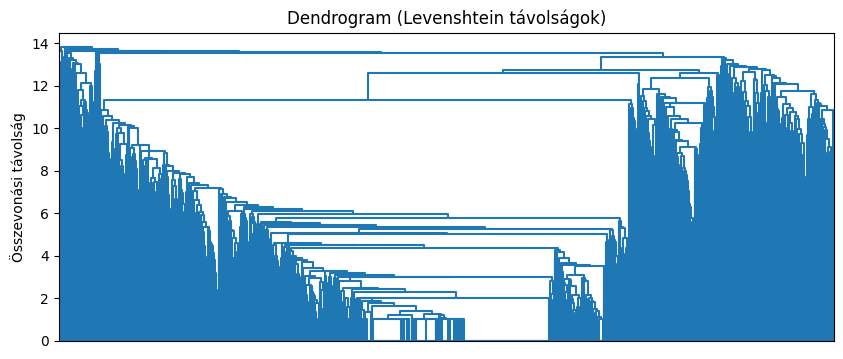

Silhouette értékek (Precomputed):
k =  2 | Silhouette = 0.2957
k =  3 | Silhouette = 0.2835
k =  4 | Silhouette = 0.2715
k =  5 | Silhouette = 0.2779
k =  6 | Silhouette = 0.2722
k =  7 | Silhouette = 0.2674
k =  8 | Silhouette = 0.2617
k =  9 | Silhouette = 0.2587
k = 10 | Silhouette = 0.2553
k = 11 | Silhouette = 0.2544
k = 12 | Silhouette = 0.3137
k = 13 | Silhouette = 0.3112
k = 14 | Silhouette = 0.3103
k = 15 | Silhouette = 0.3089


In [107]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# 1. Linkage mátrix és Dendrogram kirajzolása
condensed_dist = squareform(dist_matrix)
Z_link = linkage(condensed_dist, method='average')

plt.figure(figsize=(10, 4))
dendrogram(Z_link, no_labels=True, color_threshold=0)
plt.title("Dendrogram (Levenshtein távolságok)")
plt.ylabel("Összevonási távolság")
plt.show()

# 2. Silhouette-értékek kiszámítása k=2..15 között
print("Silhouette értékek (Precomputed):")
for k in range(2, 16):
    labels = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average').fit_predict(dist_matrix)
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    print(f"k = {k:2d} | Silhouette = {score:.4f}")

# Aggreagate sequences

In [146]:
import numpy as np
import pandas as pd
import math

grouped = df.groupby('sequence_id')
# Egyedi aggregációk kiszámítása
attacks_list = []

for sequence_id, group in grouped:
    group = group.sort_values('index')

    #volumen

    total_duration = group['duration'].sum()

    total_events = len(group)

    #passes

    passes_in_group = group[group['type'] == 'Pass']

    pass_count=len(passes_in_group)

    total_pass_length = passes_in_group['pass_length'].sum()

    mean_pass_length = passes_in_group['pass_length'].mean() if not passes_in_group.empty else 0.0

    pass_length_std = passes_in_group['pass_length'].std() if len(passes_in_group) > 1 else 0.0

    long_passes=(passes_in_group['pass_length']>=35).sum()
    long_pass_ratio=long_passes/pass_count if pass_count>0 else 0.0

    cross_count = group['pass_cross'].sum()

    switch_count = group['pass_switch'].sum()

    pass_height_sum = group['pass_height_num'].sum()
    high_pass_ratio=pass_height_sum/pass_count if pass_count >0 else 0.0

    through_ball_count = group['pass_through_ball'].sum()

    direction_counts = passes_in_group['pass_direction'].value_counts()
    forward_pass_ratio=direction_counts.get('forward', 0)/pass_count if pass_count >0 else 0.0
    side_pass_ratio=direction_counts.get('side', 0)/pass_count if pass_count >0 else 0.0
    backward_pass_ratio=(1 - (forward_pass_ratio + side_pass_ratio))

    dribble_count = len(group[group['type'] == 'Dribble'])

    #spatial

    y_coords = pd.concat([group['y'], group['pass_end_y'], group['carry_end_y']]).dropna()
    width = (y_coords.max() - y_coords.min()) if not y_coords.empty else 0.0

    start_x = group['x'].iloc[0]

    start_y = group['y'].iloc[0]

    start_y_unilat=abs(start_y-40)

    shot_x=group['x'].iloc[-1]

    shot_y=group['y'].iloc[-1]

    shot_y_unilat=abs(shot_y-40)

    d3_duration_ratio= (group[group['x_zone'] == 'defensive']['duration'].sum())/total_duration
    m3_duration_ratio= (group[group['x_zone'] == 'middle']['duration'].sum())/total_duration
    a3_duration_ratio=(1-(d3_duration_ratio + m3_duration_ratio))

    r_duration_ratio=(group[group['y_zone'] == 'right']['duration'].sum())/total_duration
    l_duration_ratio=(group[group['y_zone'] == 'left']['duration'].sum())/total_duration
    c_duration_ratio=(1-(r_duration_ratio + l_duration_ratio))

    #distance

    coords = list(zip(group['x'], group['y']))
    total_distance = sum(math.dist(coords[i], coords[i+1]) for i in range(len(coords) - 1))

    net_distance = math.dist((start_x, start_y), (shot_x, shot_y))

    carries = group[group['type'] == 'Carry']
    if not carries.empty:
      carries = carries.copy()
      carries['carry_dist'] = np.hypot(carries['carry_end_x'] - carries['x'], carries['carry_end_y'] - carries['y'])
      carry_distance = carries['carry_dist'].sum(skipna=True)
    else:
      carry_distance = 0.0
    carry_distance_ratio = carry_distance / total_distance if total_distance > 0 else 0.0

    #dynamics

    directness=net_distance/total_distance

    tempo=total_events/total_duration

    attack = {
        'sequence_id': sequence_id,
        'year': group['year'].iloc[0],
        'play_pattern': group['play_pattern'].iloc[0],
        #volumen
        'total_duration': total_duration,
        # passes
        'total_events' : total_events,
        ## direction
        'forward_pass_%': forward_pass_ratio,
        'side_pass_%': side_pass_ratio,
        'backward_pass_%': backward_pass_ratio,
        ## length
        'long_pass_%': long_pass_ratio, #+

        # spare events - special passes
        'cross_count': cross_count,
        'switch_count': switch_count, #+
        'through_ball_count': through_ball_count,
        'dribble_ratio': dribble_count/total_events, #+

        # spatial

        'start_x': start_x,
        'start_y_unilat': start_y_unilat,
        'shot_x': shot_x,
        'shot_y_unilat' : shot_y_unilat,
        'total_distance': total_distance,

        'd3_time_%': d3_duration_ratio,
        'm3_time_%':m3_duration_ratio,
        'a3_time_%':a3_duration_ratio,
        'left_time_%': l_duration_ratio,
        'right_time_%': r_duration_ratio,
        'side_time_%' : l_duration_ratio + r_duration_ratio,
        'central_time_%': c_duration_ratio,
        #dynamics
        'directness': directness,
        'tempo': tempo,
        'carry_distance_ratio': carry_distance_ratio #+
    }

    attacks_list.append(attack)


attacks_df = pd.DataFrame(attacks_list)
attacks_df.head()

,sequence_id,year,play_pattern,total_duration,total_events,forward_pass_%,side_pass_%,backward_pass_%,long_pass_%,cross_count,switch_count,through_ball_count,dribble_ratio,start_x,start_y_unilat,shot_x,shot_y_unilat,total_distance,d3_time_%,m3_time_%,a3_time_%,left_time_%,right_time_%,side_time_%,central_time_%,directness,tempo,carry_distance_ratio
0,22921_1_17_France Women's_0,2019,From Counter,9.450070,9,0.50,0.5,0.00,0.00,0,0,0,0.0,61.9,23.2,101.0,0.7,55.231634,0.0,0.394325,0.605675,0.703572,0.000000,0.703572,0.296428,0.829705,0.952374,0.364375
1,22921_1_24_France Women's_0,2019,Regular Play,7.320604,4,0.50,0.5,0.00,0.00,1,0,0,0.0,87.7,31.0,112.1,3.8,51.322707,0.0,0.000000,1.000000,0.000000,0.872851,0.872851,0.127149,0.711973,0.546403,0.498751
2,22921_1_31_France Women's_0,2019,From Corner,3.360700,3,0.00,1.0,0.00,0.50,0,1,0,0.0,120.0,40.0,97.1,10.9,64.986644,0.0,0.000000,1.000000,0.000000,0.573333,0.573333,0.426667,0.569809,0.892671,0.000000
3,22921_1_46_France Women's_0,2019,From Corner,1.742400,2,0.00,1.0,0.00,1.00,0,0,0,0.0,120.0,40.0,95.7,10.1,38.529210,0.0,0.000000,1.000000,0.000000,0.852560,0.852560,0.147440,1.000000,1.147842,0.000000
4,22921_1_46_France Women's_1,2019,From Corner,14.401026,7,0.25,0.5,0.25,0.25,1,0,0,0.0,84.3,9.3,109.7,2.9,123.016789,0.0,0.491402,0.508598,0.137351,0.000000,0.137351,0.862649,0.229058,0.486076,0.075940


In [109]:
attacks_df.describe()

,year,total_duration,total_events,forward_pass_%,side_pass_%,backward_pass_%,long_pass_%,cross_count,switch_count,through_ball_count,dribble_ratio,start_x,start_y_unilat,shot_x,shot_y_unilat,total_distance,d3_time_%,m3_time_%,a3_time_%,left_time_%,right_time_%,side_time_%,central_time_%,directness,tempo,carry_distance_ratio
count,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2.690000e+03,2690.000000,2690.000000,2690.000000
mean,2021.212639,17.688504,11.184758,0.191832,0.714440,0.093727,0.252127,0.328253,0.169888,0.047212,0.019557,74.094758,26.134387,104.449442,7.553420,141.565104,0.116137,0.283096,0.600768,0.311106,0.339092,0.650199,3.498014e-01,0.578263,0.725579,0.203094
std,1.989034,18.076084,10.849235,0.242945,0.291155,0.196973,0.350739,0.543104,0.405137,0.213877,0.047358,35.809659,14.173037,8.511529,5.668846,136.359983,0.184616,0.275866,0.343382,0.308854,0.315796,0.253196,2.531961e-01,0.316029,0.305781,0.200448
min,2019.000000,0.423239,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,61.400000,0.000000,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-2.220446e-16,0.018157,0.142513,0.000000
25%,2019.000000,4.572163,3.000000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,46.900000,13.325000,98.700000,2.800000,46.403067,0.000000,0.000000,0.288665,0.000000,0.000000,0.526412,1.727980e-01,0.291798,0.562720,0.055556
50%,2023.000000,12.205746,8.000000,0.125000,0.750000,0.000000,0.095238,0.000000,0.000000,0.000000,0.000000,76.400000,30.200000,106.100000,6.300000,96.394579,0.000000,0.263963,0.558692,0.256697,0.281263,0.691467,3.085334e-01,0.554588,0.667293,0.173385
75%,2023.000000,23.821108,15.000000,0.333333,1.000000,0.125000,0.333333,1.000000,0.000000,0.000000,0.000000,107.850000,39.900000,111.100000,11.500000,194.123556,0.198439,0.502926,1.000000,0.546352,0.592459,0.827202,4.735875e-01,0.914553,0.805045,0.276126
max,2023.000000,196.912904,132.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000,2.000000,0.333333,120.000000,40.000000,119.600000,39.400000,1473.130956,0.933278,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000,4.725462,1.005327


In [4]:
pd.set_option('display.max_columns', None)

In [ ]:

longest=wwc_games[wwc_games["match_id"]==3893822]
longest
#spanyoloknak 68% volt a possession, mégis 4-0ra sz

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,competition_id,competition_country_name,competition_name,competition,season_id,season,home_team_id,home_team,home_team_gender,home_team_group,home_team_country_id,home_team_country_name,away_team_id,away_team,away_team_gender,away_team_group,away_team_country_id,away_team_country_name,competition_stage_id,competition_stage,stadium_id,stadium,stadium_country_id,stadium_country_name,referee_id,referee,referee_country_id,referee_country_name,home_managers,away_managers,home_manager_id,home_manager_name,home_manager_nickname,home_manager_dob,home_manager_country_id,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
97,3893822,2023-07-31,07:00:00.000,4,0,available,available,2026-05-03T13:49:41.352078,2026-05-03T13:55:33.041563,3,72,International,Women's World Cup,International - Women's World Cup,107,2023,1210,Japan Women's,female,None,114,Japan,863,Spain Women's,female,None,214,Spain,10,Group Stage,98115,Wellington Regional Stadium,14,Australia,751.0,Katja Koroleva,241.0,United States of America,Futoshi Ikeda,Jorge Vilda,1003258,Futoshi Ikeda,None,1970-10-04,114,Japan,418,Jorge Vilda,None,1981-07-07,214,Spain,1.1.0,2,2


In [5]:
attacks_df.columns

Index(['sequence_id', 'year', 'total_duration', 'total_events',
       'forward_pass_%', 'side_pass_%', 'backward_pass_%', 'long_pass_%',
       'cross_count', 'switch_count', 'through_ball_count', 'dribble_ratio',
       'start_x', 'start_y_unilat', 'shot_x', 'shot_y_unilat',
       'total_distance', 'd3_time_%', 'm3_time_%', 'a3_time_%', 'left_time_%',
       'right_time_%', 'side_time_%', 'central_time_%', 'directness', 'tempo',
       'carry_distance_ratio'],
      dtype='object')

In [147]:
attacks=attacks_df.copy()

In [148]:
exclude_patterns=["From Corner", "From Free Kick"]
attacks=attacks[~attacks["play_pattern"].isin(exclude_patterns)]
attacks.describe()

,year,total_duration,total_events,forward_pass_%,side_pass_%,backward_pass_%,long_pass_%,cross_count,switch_count,through_ball_count,dribble_ratio,start_x,start_y_unilat,shot_x,shot_y_unilat,total_distance,d3_time_%,m3_time_%,a3_time_%,left_time_%,right_time_%,side_time_%,central_time_%,directness,tempo,carry_distance_ratio
count,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1802.000000,1.802000e+03,1802.000000,1802.000000,1802.000000
mean,2021.208657,22.121857,13.863485,0.239351,0.649458,0.111191,0.118230,0.362375,0.105438,0.058824,0.025430,61.677580,23.525527,103.394395,8.323918,169.791101,0.150079,0.360251,0.489670,0.322322,0.324215,0.646537,3.534631e-01,0.482146,0.689864,0.262855
std,1.989638,18.680608,11.260048,0.242755,0.277746,0.204050,0.183073,0.560780,0.341443,0.235359,0.051878,31.914418,14.374638,8.521021,5.897305,143.483449,0.198409,0.261113,0.310717,0.297995,0.298447,0.255671,2.556706e-01,0.273473,0.272921,0.189191
min,2019.000000,0.479082,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.200000,0.000000,61.400000,0.000000,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-2.220446e-16,0.018157,0.142513,0.000000
25%,2019.000000,9.473025,6.000000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,38.050000,9.500000,97.600000,3.200000,71.680442,0.000000,0.133446,0.236576,0.000000,0.000000,0.512820,1.707172e-01,0.248324,0.549010,0.150989
50%,2023.000000,16.798458,11.000000,0.200000,0.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,63.550000,23.850000,104.750000,7.500000,133.440258,0.000000,0.373546,0.412653,0.279478,0.269610,0.687242,3.127581e-01,0.445584,0.643927,0.222267
75%,2023.000000,28.635032,18.000000,0.333333,0.833333,0.153846,0.180481,1.000000,0.000000,0.000000,0.030303,87.300000,39.900000,109.800000,12.500000,223.155215,0.273909,0.555441,0.737925,0.526251,0.513211,0.829283,4.871797e-01,0.693891,0.762549,0.316973
max,2023.000000,196.912904,132.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000,1.000000,0.333333,119.500000,40.000000,119.000000,39.400000,1473.130956,0.933278,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000,4.174651,1.005327


In [149]:
attacks=attacks[attacks['total_events']>2].copy()
cols_keep=[ #'sequence_id', 'year',
            #'total_duration',
            'total_events',
            'forward_pass_%', 'side_pass_%', #'backward_pass_%',
            'long_pass_%', 'cross_count',
            #'switch_count', 'through_ball_count',
            'dribble_ratio',
            'start_x','start_y_unilat',
            'shot_x', 'shot_y_unilat',
            #'total_distance',
            'd3_time_%', 'm3_time_%', #'a3_time_%',
            'side_time_%', #'central_time_%',
            'directness', 'tempo',
            'carry_distance_ratio']
attacks_filtered = attacks[cols_keep]

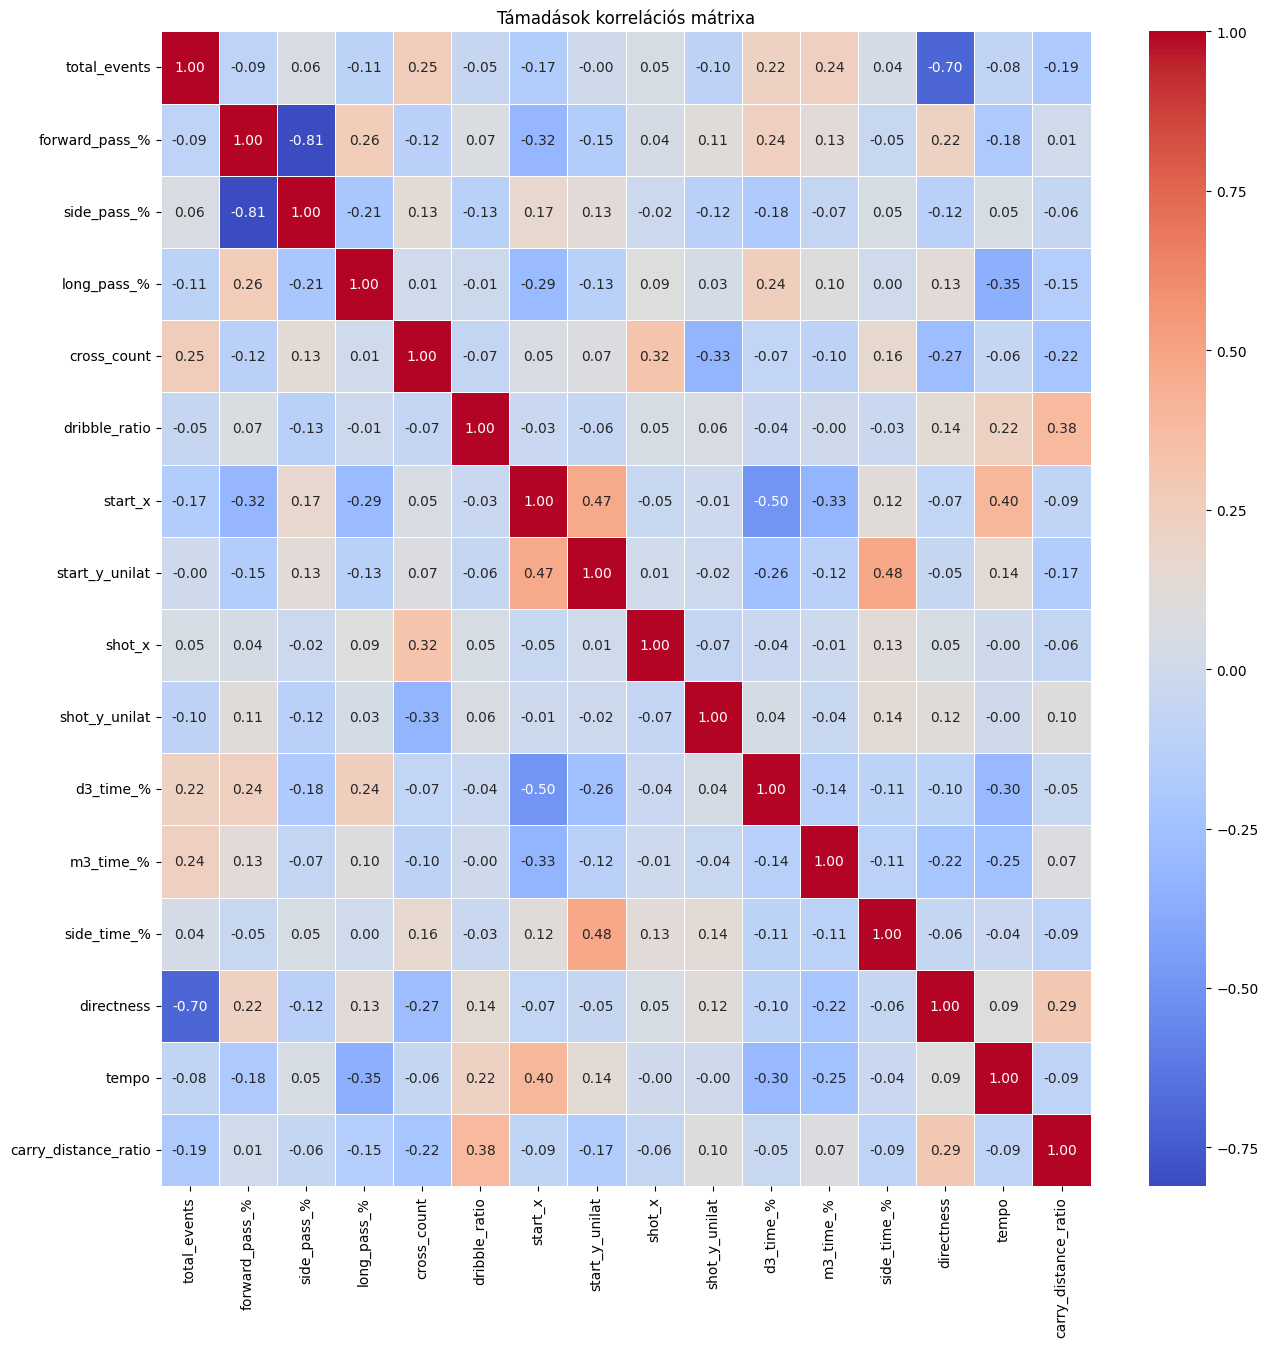

In [150]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix=attacks_filtered.corr()

# Ábrázolás hőtérképpel
plt.figure(figsize=(15, 15))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Támadások korrelációs mátrixa")
plt.show()

In [ ]:
# @title
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro

# Feltételezve, hogy az adataid a 'df' nevű DataFrame-ben vannak
for column in attacks_filtered.columns:
    data = attacks_filtered[column].dropna()

    plt.figure(figsize=(6, 4))
    sns.histplot(data, kde=True, bins=30)
    plt.title(f'Hisztogram: {column}')
    plt.show()

    stat, p_value = shapiro(data)
    print(f'{column} | Shapiro-Wilk statisztika: {stat:.4f}, p-érték: {p_value:.5f}')

In [151]:
from sklearn.preprocessing import RobustScaler


scaler = RobustScaler()

attacks_scaled = scaler.fit_transform(attacks_filtered)
attacks_scaled_df = pd.DataFrame(attacks_scaled, columns=attacks_filtered.columns)
attacks_scaled_df.head()

,total_events,forward_pass_%,side_pass_%,long_pass_%,cross_count,dribble_ratio,start_x,start_y_unilat,shot_x,shot_y_unilat,d3_time_%,m3_time_%,side_time_%,directness,tempo,carry_distance_ratio
0,-0.181818,0.90,-0.500000,0.000000,0.0,0.000000,-0.010235,-0.043333,-0.295082,-0.731183,-0.157795,0.029636,0.043343,0.931893,1.481047,0.901959
1,-0.636364,0.90,-0.500000,0.000000,1.0,0.000000,0.517912,0.216667,0.614754,-0.397849,-0.157795,-0.975072,0.600824,0.655531,-0.459977,1.748681
2,0.545455,-0.60,0.333333,0.611111,0.0,0.000000,0.255885,0.516667,0.295082,0.397849,-0.157795,-0.134253,0.054175,-0.549805,-0.264865,-0.270156
3,1.363636,-0.35,0.250000,0.458333,1.0,1.153846,-0.679632,-0.730000,-0.024590,1.182796,1.431292,-0.146152,-0.720504,-0.433830,0.010040,0.327074
4,0.000000,0.40,0.000000,0.000000,1.0,0.000000,-0.186285,-0.236667,0.098361,1.053763,-0.157795,0.300755,0.508339,0.108569,1.358324,-0.140222


## UMAP + HDBSCAN

In [49]:

!pip install hdbscan


In [157]:
import umap
import hdbscan
import matplotlib.pyplot as plt
import seaborn as sns

# 1. UMAP dimenziócsökkentés (a RobustScaler-rel skálázott adatokon)
# n_neighbors: 15-30 közötti érték javasolt (lokális vs. globális struktúra egyensúlya)
umap_reducer = umap.UMAP(
    n_neighbors=13,
    min_dist=0.0,
    n_components=5,
    random_state=42
)
attacks_umap = umap_reducer.fit_transform(attacks_scaled)




In [165]:
# 2. HDBSCAN klaszterezés a UMAP által transzformált téren
cluster_labels_final=clusterer = hdbscan.HDBSCAN(
    min_cluster_size=40,   # 2690 adatra kb. 1-2%
    min_samples=13,        # Finomhangolás a zajszűréshez
    metric='euclidean',
    cluster_selection_method='eom').fit_predict(attacks_umap)


counts = pd.Series(cluster_labels_final).value_counts().sort_index()

noise_count = counts.get(-1, 0)
noise_pct = (noise_count / len(cluster_labels_final)) * 100
print(f"Zaj (-1) elemszáma: {noise_count} ({noise_pct:.2f}%)")
for cluster_id, count in counts.items():
  name = "Zaj (-1)" if cluster_id == -1 else f"Klaszter {cluster_id}"
  print(f"  {name}: {count} db ({count / len(cluster_labels_final) * 100:.2f}%)")

Zaj (-1) elemszáma: 145 (8.34%)
  Zaj (-1): 145 db (8.34%)
  Klaszter 0: 530 db (30.48%)
  Klaszter 1: 120 db (6.90%)
  Klaszter 2: 501 db (28.81%)
  Klaszter 3: 150 db (8.63%)
  Klaszter 4: 87 db (5.00%)
  Klaszter 5: 80 db (4.60%)
  Klaszter 6: 126 db (7.25%)


In [185]:
import pandas as pd
from IPython.display import display


attacks['cluster_hdbscan'] = cluster_labels_final

# Klaszterek jellemzőinek átlaga
profiles_mean = cluster_profiles.groupby('cluster_hdbscan').mean()

display(profiles_mean.round(3))

,total_events,forward_pass_%,side_pass_%,long_pass_%,cross_count,dribble_ratio,start_x,start_y_unilat,shot_x,shot_y_unilat,d3_time_%,m3_time_%,side_time_%,directness,tempo,carry_distance_ratio
cluster_hdbscan,,,,,,,,,,,,,,,,
-1,10.669,0.258,0.655,0.133,0.290,0.000,67.009,29.961,101.046,8.614,0.136,0.391,0.723,0.494,0.674,0.226
0,20.623,0.256,0.648,0.111,0.455,0.086,55.126,22.932,104.700,8.246,0.178,0.406,0.652,0.392,0.709,0.288
1,7.367,0.510,0.439,0.001,0.008,0.000,62.060,16.003,99.239,9.519,0.163,0.401,0.501,0.641,0.648,0.312
2,13.457,0.284,0.629,0.241,0.525,0.000,43.788,20.013,105.022,7.003,0.238,0.398,0.649,0.451,0.576,0.196
3,19.280,0.188,0.691,0.074,0.053,0.000,75.853,30.987,100.286,11.081,0.060,0.494,0.707,0.233,0.689,0.206
4,4.977,0.000,0.989,0.000,0.115,0.000,71.202,21.715,101.602,9.663,0.045,0.340,0.603,0.733,0.555,0.499
5,7.612,0.174,0.764,0.000,0.962,0.000,91.091,32.207,109.398,4.266,0.010,0.108,0.779,0.591,0.750,0.149
6,6.500,0.070,0.759,0.000,0.056,0.000,93.187,30.658,98.517,11.181,0.027,0.078,0.670,0.618,0.969,0.210


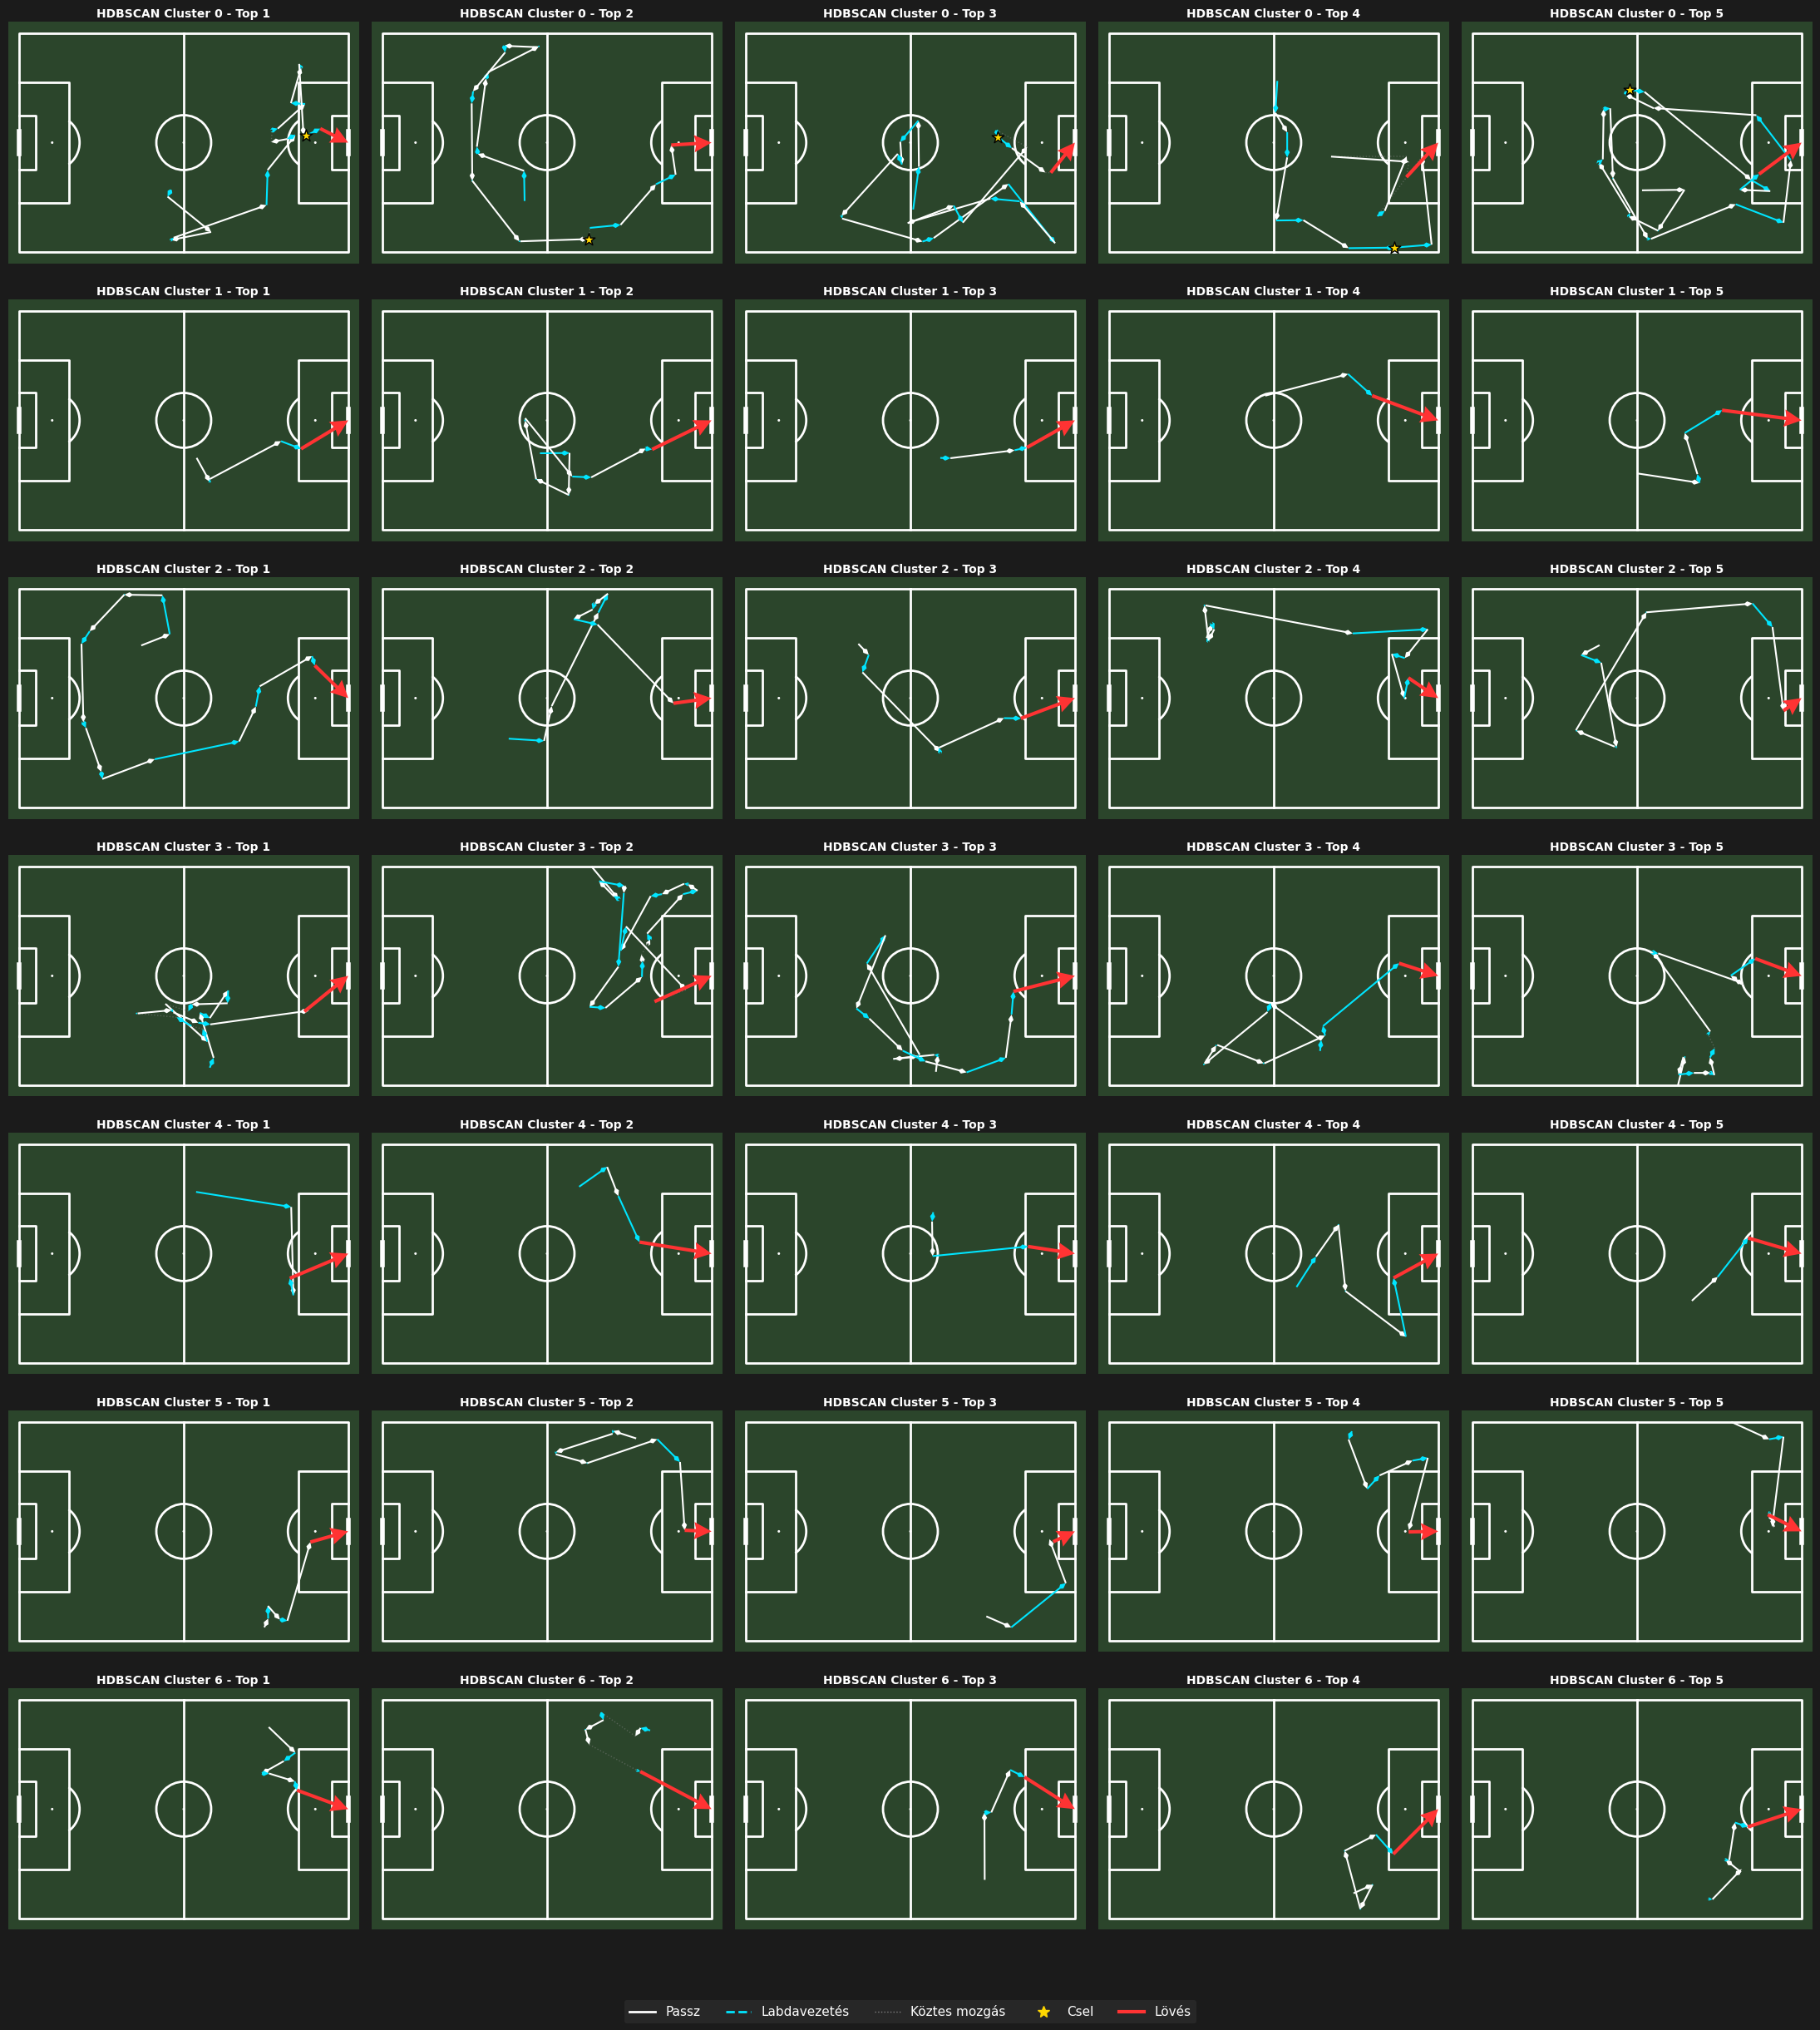

In [167]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

try:
    from mplsoccer import Pitch
except ImportError:
    !pip install mplsoccer
    from mplsoccer import Pitch

# 1. HDBSCAN adatok és átlagok előkészítése
cluster_profiles = attacks_filtered.copy()
cluster_profiles['cluster_hdbscan'] = cluster_labels_final

# Kiszűrjük a zajpontokat (-1) a vizualizációból
unique_clusters = sorted([c for c in cluster_profiles['cluster_hdbscan'].unique() if c != -1])
k_hdbscan = len(unique_clusters)
top_n = 5

# 2. Pályák inicializálása HDBSCAN klaszterszám alapján
pitch = Pitch(pitch_type='statsbomb', pitch_color='#2b452b', line_color='white')
fig, axes = pitch.draw(nrows=k_hdbscan, ncols=top_n, figsize=(22, 3.5 * k_hdbscan))
fig.patch.set_facecolor('#1b1b1b')

# 3. Klaszterenként a legközelebbi 5 támadás kikeresése a klaszterközépponthoz képest
for row_idx, cluster_id in enumerate(unique_clusters):
    cluster_mask = (cluster_profiles['cluster_hdbscan'] == cluster_id)
    cluster_data = attacks_filtered[cluster_mask]

    # Klaszter középértéke (centroidja) az alapadatok térbeli átlaga alapján
    cluster_center = cluster_data.mean(axis=0).values.reshape(1, -1)

    # Euklideszi távolságok a klaszterközépponttól
    dists = cdist(cluster_data, cluster_center, metric='euclidean').flatten()
    top5_local_indices = np.argsort(dists)[:top_n]
    # JAVÍTÁS: .iloc helyett .loc-ot használunk, mert a cluster_data.index címkéket tartalmaz
    top5_seq_ids = attacks.loc[cluster_data.index[top5_local_indices]]['sequence_id'].values

    for sample_idx, seq_id in enumerate(top5_seq_ids):
        ax = axes[row_idx, sample_idx] if k_hdbscan > 1 else axes[sample_idx]
        ax.set_title(f'HDBSCAN Cluster {cluster_id} - Top {sample_idx+1}', color='white', fontsize=10, fontweight='bold', pad=4)

        seq_events = df[df['sequence_id'] == seq_id].sort_values('index')

        prev_end_x, prev_end_y = None, None
        for _, event in seq_events.iterrows():
            curr_x, curr_y = event['x'], event['y']

            # Koordinátahézag áthidalása halvány szürke pontozott vonallal
            if prev_end_x is not None and (prev_end_x != curr_x or prev_end_y != curr_y):
                ax.plot([prev_end_x, curr_x], [prev_end_y, curr_y], color='gray', linestyle=':', linewidth=1, alpha=0.5, zorder=2)

            # Passz
            if pd.notna(event.get('pass_end_x')) and pd.notna(event.get('pass_end_y')):
                pitch.arrows(event['x'], event['y'], event['pass_end_x'], event['pass_end_y'], ax=ax, color='white', width=1.5, headwidth=3, headlength=3, zorder=3)
                prev_end_x, prev_end_y = event['pass_end_x'], event['pass_end_y']
            # Labdavezetés
            elif pd.notna(event.get('carry_end_x')) and pd.notna(event.get('carry_end_y')):
                pitch.arrows(event['x'], event['y'], event['carry_end_x'], event['carry_end_y'], ax=ax, color='#00e5ff', width=1.5, headwidth=3, headlength=3, linestyle='--', zorder=3)
                prev_end_x, prev_end_y = event['carry_end_x'], event['carry_end_y']
            else:
                prev_end_x, prev_end_y = curr_x, curr_y

            # Csel
            if event.get('type') == 'Dribble' or event.get('dribble_ratio', 0) > 0:
                ax.scatter(event['x'], event['y'], marker='*', color='gold', s=120, edgecolors='black', zorder=5)
            # Lövés
            if event.get('type') == 'Shot' or pd.notna(event.get('shot_x')):
                shot_x = event.get('shot_x', event['x'])
                shot_y = event.get('shot_y', event['y'])
                pitch.arrows(shot_x, shot_y, 120, 40, ax=ax, color='#ff3333', width=3, headwidth=5, headlength=5, zorder=6)

# 4. Jelmagyarázat
legend_elements = [
    plt.Line2D([0], [0], color='white', lw=2, label='Passz'),
    plt.Line2D([0], [0], color='#00e5ff', lw=2, linestyle='--', label='Labdavezetés'),
    plt.Line2D([0], [0], color='gray', lw=1, linestyle=':', label='Köztes mozgás'),
    plt.Line2D([0], [0], marker='*', color='gold', label='Csel', markerfacecolor='gold', markersize=10, linestyle='None'),
    plt.Line2D([0], [0], color='#ff3333', lw=3, label='Lövés')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=5, fontsize=11, frameon=True, facecolor='#2b2b2b', edgecolor='none', labelcolor='white')

plt.tight_layout()
plt.subplots_adjust(bottom=0.04)
plt.show()

In [189]:
import pandas as pd
import numpy as np

TOP_N=5

# 1. Használjuk a szűrt/skálázott jellemzőket és adjuk hozzá a klasztercímkéket
features_df = pd.DataFrame(attacks_scaled, columns=attacks_filtered.columns)
features_df['cluster'] = cluster_labels_final

#

# 2. Számoljuk ki a klaszterek átlagát és a globális átlagot a skálázott térben
cluster_means = features_df.groupby('cluster').mean()
global_means = features_df.drop(columns='cluster').mean()

# 3. Klaszterenként határozzuk meg a legnagyobb pozitív eltérést mutató top 3 jellemzőt (lift)
print(f"=== A klaszterekre leginkább jellemző {TOP_N} tulajdonság ===\n")
for cluster_id in sorted(features_df['cluster'].unique()):
    # Különbség a klaszterátlag és a globális átlag között
    diffs = cluster_means.loc[cluster_id] - global_means

    # Top 3 rendezése csökkenő sorrendbe (legnagyobb pozitív lift)
    top3_features = diffs.sort_values(ascending=False).head(TOP_N)

    # Eredeti (skálázatlan) átlagok lekérése a könnyebb értelmezhetőségért
    original_cluster = attacks.loc[attacks['cluster_hdbscan'] == cluster_id, attacks_filtered.columns].mean()
    original_global = attacks[attacks_filtered.columns].mean()

    print(f"Klaszter {cluster_id} (n = {sum(features_df['cluster'] == cluster_id)} támadás):")
    for feat, lift_val in top3_features.items():
        c_val = original_cluster[feat]
        g_val = original_global[feat]
        # Formázás: ha arány, akkor %, ha egész szám, tizedesjegyekkel
        if '%' in feat or 'ratio' in feat:
            print(f"  - {feat:<22} | Klaszter átlag: {c_val:.1%}, Globális átlag: {g_val:.1%} (Lift: {lift_val:+.2f})")
        else:
            print(f"  - {feat:<22} | Klaszter átlag: {c_val:.2f}, Globális átlag: {g_val:.2f} (Lift: {lift_val:+.2f})")
    print()

=== A klaszterekre leginkább jellemző 5 tulajdonság ===

Klaszter -1 (n = 145 támadás):
  - side_time_%            | Klaszter átlag: 72.3%, Globális átlag: 65.6% (Lift: +0.22)
  - start_y_unilat         | Klaszter átlag: 29.96, Globális átlag: 23.82 (Lift: +0.20)
  - start_x                | Klaszter átlag: 67.01, Globális átlag: 60.33 (Lift: +0.14)
  - directness             | Klaszter átlag: 0.49, Globális átlag: 0.46 (Lift: +0.07)
  - long_pass_%            | Klaszter átlag: 13.3%, Globális átlag: 12.1% (Lift: +0.07)

Klaszter 0 (n = 530 támadás):
  - dribble_ratio          | Klaszter átlag: 8.6%, Globális átlag: 2.6% (Lift: +1.79)
  - total_events           | Klaszter átlag: 20.62, Globális átlag: 14.29 (Lift: +0.58)
  - carry_distance_ratio   | Klaszter átlag: 28.8%, Globális átlag: 24.9% (Lift: +0.25)
  - tempo                  | Klaszter átlag: 0.71, Globális átlag: 0.67 (Lift: +0.16)
  - shot_x                 | Klaszter átlag: 104.70, Globális átlag: 103.34 (Lift: +0.11)

Klas

In [163]:
import hdbscan
import umap
import pandas as pd

results = []

# Grid Search futtatása a UMAP és HDBSCAN paraméterekre
for n_neigh in [ 13, 27, 40, 54]:
  for n_comps in [3,4,5,6]:
    reducer = umap.UMAP(n_neighbors=n_neigh, min_dist=0.0, n_components=n_comps, random_state=42)
    umap_emb = reducer.fit_transform(attacks_scaled)

    for mcs in [27, 40, 54, 108]:
        for ms in [13, 20, 27, 40]:
            clusterer = hdbscan.HDBSCAN(min_cluster_size=mcs, cluster_selection_method='eom', min_samples=ms, gen_min_span_tree=True)
            labels = clusterer.fit_predict(umap_emb)

            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            noise_pct = (labels == -1).sum() / len(labels) * 100

            # DBCV kiszámítása (ha legalább 2 klaszter keletkezett)
            dbcv_score = clusterer.relative_validity_ if n_clusters > 1 else -1

            results.append({
                'n_neighbors': n_neigh,
                'n_components': n_comps,
                'min_cluster_size': mcs,
                'min_samples': ms,
                'n_clusters': n_clusters,
                'noise_pct': round(noise_pct, 2),
                'DBCV': round(dbcv_score, 4)
            })

df_res = pd.DataFrame(results)



In [164]:
print(df_res.sort_values(by='DBCV', ascending=False).head(10))

     n_neighbors  n_components  min_cluster_size  min_samples  n_clusters  \
36            13             5                40           13           7   
32            13             5                27           13           7   
156           40             4               108           13           6   
71            27             3                40           40           6   
67            27             3                27           40           6   
66            27             3                27           27           4   
74            27             3                54           27           4   
70            27             3                40           27           4   
197           54             3                40           20           4   
201           54             3                54           20           4   

     noise_pct    DBCV  
36        8.34  0.5008  
32        8.34  0.5008  
156      19.61  0.4473  
71       26.97  0.4305  
67       26.97  0.4305  
66

## PCA + KMeans

In [71]:
!pip install factor_analyzer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=8221c437a2dbf0188b9efb78fe704537c1234e6a51506064d062a0ced4d90b60
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [168]:
from factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

# 1. Bartlett-teszt (p < 0.05 esetén a PCA módszertanilag megalapozott)
chi2, p_val = calculate_bartlett_sphericity(attacks_scaled)
print(f"Bartlett-teszt chi2: {chi2:.2f}, p-érték: {p_val:.5f}")

# 2. KMO-teszt (> 0.6 elfogadható mintavételi adekvátság)
kmo_vars, kmo_model = calculate_kmo(attacks_scaled)
print(f"KMO összegzett érték: {kmo_model:.4f}")

Bartlett-teszt chi2: 8709.40, p-érték: 0.00000
KMO összegzett érték: 0.5286


In [169]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA

# 1. PCA illesztése a skálázott adathalmazra
pca = PCA().fit(attacks_scaled)

# 2. Sajátértékek és variancia-mutatók kiszámítása
eigenvalues = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(var_ratio)

# 3. Összefoglaló DataFrame összeállítása és megjelenítése
pca_results_df = pd.DataFrame({
    'Főkomponens': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Sajátérték (Eigenvalue)': np.round(eigenvalues, 4),
    'Magyarázott variancia (%)': np.round(var_ratio, 2),
    'Kumulált variancia (%)': np.round(cum_var, 2)
})

print(pca_results_df.to_string(index=False))

Főkomponens  Sajátérték (Eigenvalue)  Magyarázott variancia (%)  Kumulált variancia (%)
        PC1                   2.8159                      24.61                   24.61
        PC2                   1.7951                      15.69                   40.31
        PC3                   1.4144                      12.36                   52.67
        PC4                   1.0108                       8.84                   61.51
        PC5                   0.8664                       7.57                   69.08
        PC6                   0.7156                       6.25                   75.33
        PC7                   0.5507                       4.81                   80.15
        PC8                   0.5113                       4.47                   84.62
        PC9                   0.4223                       3.69                   88.31
       PC10                   0.3719                       3.25                   91.56
       PC11                   0.

In [170]:
# 3. Határozzuk meg, hány komponens sajátértéke nagyobb, mint 1
n_comps = sum(eigenvalues > 1)

# 4. Loading mátrix előállítása
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings, index=attacks_filtered.columns, columns=[f'PC{i+1}' for i in range(len(eigenvalues))])

# 5. PC1, PC2, PC3 ... kiíratása, ahol a loading abszolút értéke > 0.30 (és a top 3 kiemelése)
for col in loadings_df.columns[:n_comps]:
    print(f"=== {col} (Sajátérték: {eigenvalues[int(col[2:])-1]:.4f}) ===")
    # Szűrés a > 0.30 abszolút értékű terhelésekre
    significant_loadings = loadings_df[col][loadings_df[col].abs() > 0.30]
    # Sorbarendezés az abszolút érték alapján csökkenőleg a legfontosabbak bemutatására
    significant_loadings_sorted = significant_loadings.reindex(significant_loadings.abs().sort_values(ascending=False).index)

    if not significant_loadings_sorted.empty:
        for var, val in significant_loadings_sorted.items():
            print(f"  {var:25} | Loading: {val:+.4f}")
    else:
        print("  Nincs a megadott limittel (>0.30) rendelkező változó.")
    print()

=== PC1 (Sajátérték: 2.8159) ===
  dribble_ratio             | Loading: +1.5236
  carry_distance_ratio      | Loading: +0.5155
  tempo                     | Loading: +0.3210

=== PC2 (Sajátérték: 1.7951) ===
  tempo                     | Loading: +0.7251
  long_pass_%               | Loading: -0.7068
  forward_pass_%            | Loading: -0.4413
  start_x                   | Loading: +0.4181
  side_pass_%               | Loading: +0.3963
  d3_time_%                 | Loading: -0.3622

=== PC3 (Sajátérték: 1.4144) ===
  total_events              | Loading: +0.9482
  directness                | Loading: -0.4589

=== PC4 (Sajátérték: 1.0108) ===
  carry_distance_ratio      | Loading: +0.6570
  tempo                     | Loading: -0.4202
  long_pass_%               | Loading: -0.3706



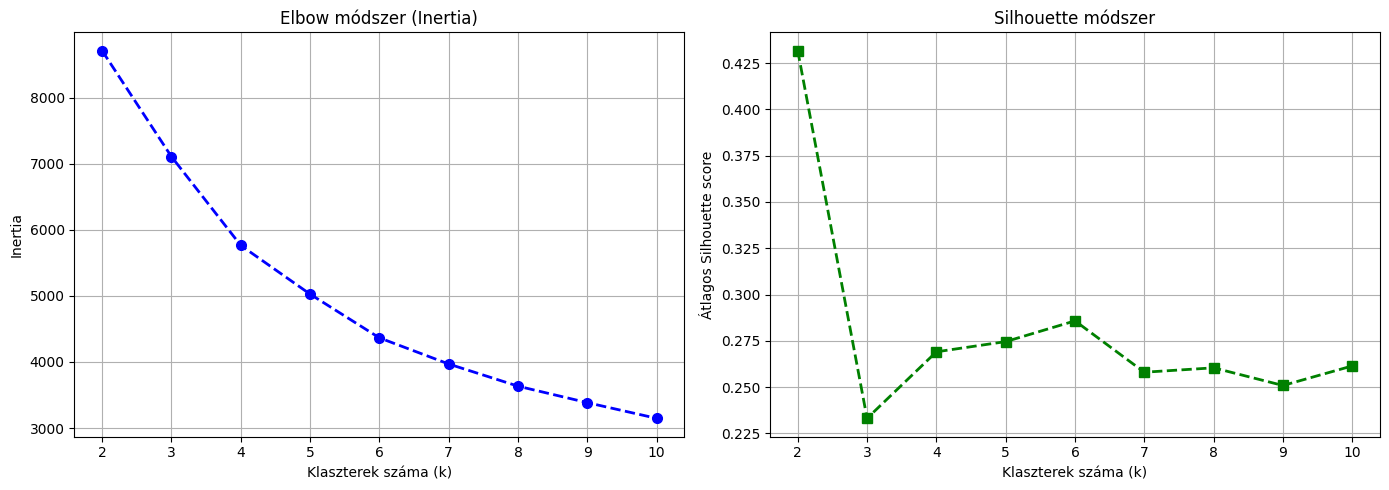

In [171]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Transzformáció a 3 megtartott főkomponensre (PC1-PC3)
pca_3d = PCA(n_components=n_comps, random_state=42)
attacks_pca_3d = pca_3d.fit_transform(attacks_scaled)

# 2. KMeans mutatók kiszámítása k=2..10 tartományban
k_range = range(2, 11)
inertias, silhouettes = [], []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(attacks_pca_3d)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(attacks_pca_3d, labels))

# 3. Elbow és Silhouette grafikonok kirajzolása
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
ax1.plot(k_range, inertias, 'bo--', linewidth=2, markersize=7)
ax1.set_title('Elbow módszer (Inertia)')
ax1.set_xlabel('Klaszterek száma (k)')
ax1.set_ylabel('Inertia')
ax1.set_xticks(k_range)
ax1.grid(True)

# Silhouette plot
ax2.plot(k_range, silhouettes, 'gs--', linewidth=2, markersize=7)
ax2.set_title('Silhouette módszer')
ax2.set_xlabel('Klaszterek száma (k)')
ax2.set_ylabel('Átlagos Silhouette score')
ax2.set_xticks(k_range)
ax2.grid(True)

plt.tight_layout()
plt.show()

In [172]:
k = 6
top_n = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(attacks_pca_3d)

In [174]:
attacks['cluster_kmeans'] = cluster_labels
print(f"\nKlaszterenkénti eloszlás:\n{attacks['cluster_kmeans'].value_counts().sort_index()}")


Klaszterenkénti eloszlás:
cluster_kmeans
0    283
1    449
2    379
3     89
4    298
5    241
Name: count, dtype: int64


In [175]:
import plotly.express as px

# Hozzunk létre egy DataFrame-et a 3D PCA első 3 koordinátájával és a klasztercímkékkel
df_pca_3d = pd.DataFrame(attacks_pca_3d[:, :3], columns=['PC1', 'PC2', 'PC3'])
df_pca_3d['Cluster'] = cluster_labels.astype(str)

# Interaktív 3D scatter plot kirajzolása Plotly-val
fig = px.scatter_3d(
    df_pca_3d,
    x='PC1',
    y='PC2',
    z='PC3',
    color='Cluster',
    title=f"Támadások 3D PCA vetülete a k-Means klaszterekkel (k={k})",
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.7
)

# Pontméret finomítása a jobb láthatóságért
fig.update_traces(marker=dict(size=4, line=dict(width=0.5, color='DarkSlateGrey')))
fig.update_layout(margin=dict(l=0, r=0, b=0, t=40))
fig.show()

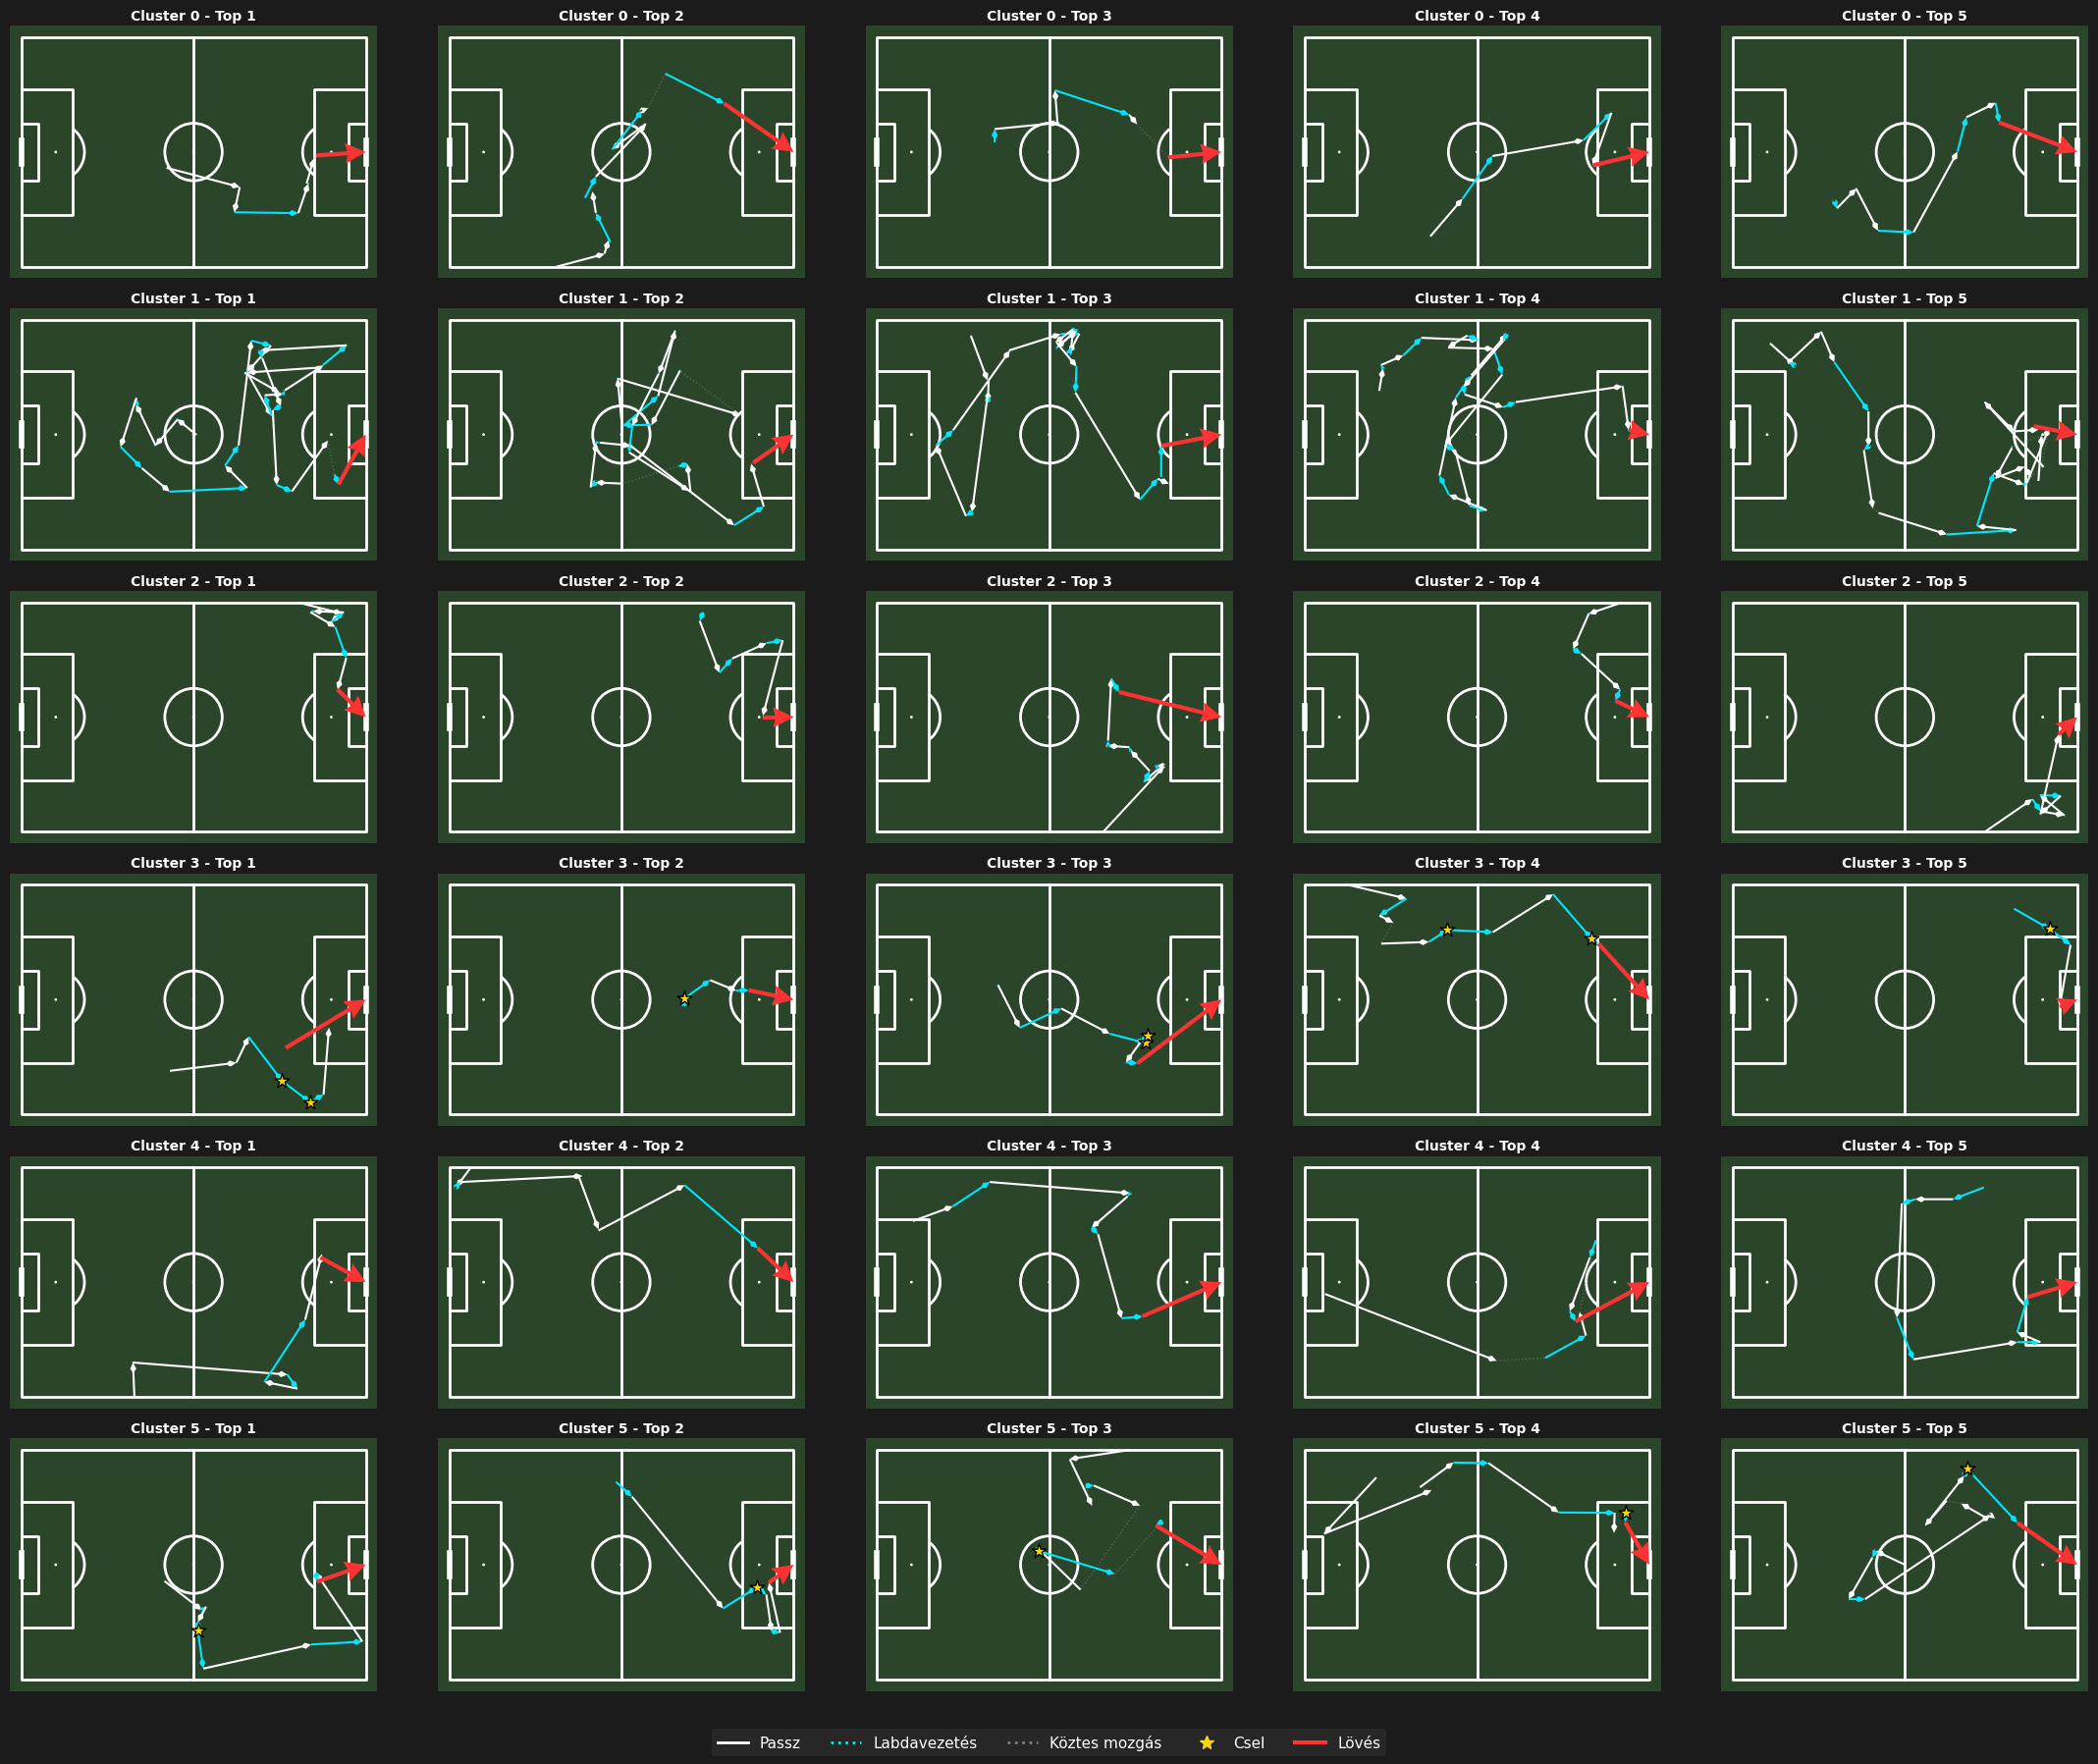

In [176]:

import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist


try:
    from mplsoccer import Pitch
except ImportError:
    !pip install mplsoccer
    from mplsoccer import Pitch



distances = cdist(attacks_pca_3d, kmeans.cluster_centers_, metric='euclidean')

# 2. Pályák inicializálása: 6 sor (klaszterek), 5 oszlop (top 5 támadás/klaszter)
pitch = Pitch(pitch_type='statsbomb', pitch_color='#2b452b', line_color='white')
fig, axes = pitch.draw(nrows=k, ncols=top_n, figsize=(22, 18))
fig.patch.set_facecolor('#1b1b1b')

# 3. Klaszterenként a top 5 legközelebbi támadás kirajzolása
for cluster_id in range(k):
    cluster_mask = (cluster_labels == cluster_id)
    cluster_distances = np.where(cluster_mask, distances[:, cluster_id], np.inf)
    top5_indices = np.argsort(cluster_distances)[:top_n]
    top5_seq_ids = attacks.iloc[top5_indices]['sequence_id'].values

    for sample_idx, seq_id in enumerate(top5_seq_ids):
        ax = axes[cluster_id, sample_idx]
        ax.set_title(f'Cluster {cluster_id} - Top {sample_idx+1}', color='white', fontsize=10, fontweight='bold', pad=4)

        seq_events = df[df['sequence_id'] == seq_id].sort_values('index')

        prev_end_x, prev_end_y = None, None
        for _, event in seq_events.iterrows():
            curr_x, curr_y = event['x'], event['y']

            # Koordinátahézag áthidalása halvány szürke pontozott vonallal
            if prev_end_x is not None and (prev_end_x != curr_x or prev_end_y != curr_y):
                ax.plot([prev_end_x, curr_x], [prev_end_y, curr_y], color='gray', linestyle=':', linewidth=1, alpha=0.5, zorder=2)

            # Passz
            if pd.notna(event.get('pass_end_x')) and pd.notna(event.get('pass_end_y')):
                pitch.arrows(event['x'], event['y'], event['pass_end_x'], event['pass_end_y'], ax=ax, color='white', width=1.5, headwidth=3, headlength=3, zorder=3)
                prev_end_x, prev_end_y = event['pass_end_x'], event['pass_end_y']
            # Labdavezetés
            elif pd.notna(event.get('carry_end_x')) and pd.notna(event.get('carry_end_y')):
                pitch.arrows(event['x'], event['y'], event['carry_end_x'], event['carry_end_y'], ax=ax, color='#00e5ff', width=1.5, headwidth=3, headlength=3, linestyle='--', zorder=3)
                prev_end_x, prev_end_y = event['carry_end_x'], event['carry_end_y']
            else:
                prev_end_x, prev_end_y = curr_x, curr_y

            # Csel
            if event.get('type') == 'Dribble' or event.get('dribble_ratio', 0) > 0:
                ax.scatter(event['x'], event['y'], marker='*', color='gold', s=120, edgecolors='black', zorder=5)
            # Lövés
            if event.get('type') == 'Shot' or pd.notna(event.get('shot_x')):
                shot_x = event.get('shot_x', event['x'])
                shot_y = event.get('shot_y', event['y'])
                pitch.arrows(shot_x, shot_y, 120, 40, ax=ax, color='#ff3333', width=3, headwidth=5, headlength=5, zorder=6)

# 4. Jelmagyarázat
legend_elements = [
    plt.Line2D([0], [0], color='white', lw=2, label='Passz'),
    plt.Line2D([0], [0], color='#00e5ff', lw=2, linestyle=':', label='Labdavezetés'),
    plt.Line2D([0], [0], color='gray', lw=2, linestyle=':', label='Köztes mozgás'),
    plt.Line2D([0], [0], marker='*', color='gold', label='Csel', markerfacecolor='gold', markersize=10, linestyle='None'),
    plt.Line2D([0], [0], color='#ff3333', lw=3, label='Lövés')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=5, fontsize=11, frameon=True, facecolor='#2b2b2b', edgecolor='none', labelcolor='white')

plt.tight_layout()
plt.subplots_adjust(bottom=0.04)
plt.show()

In [190]:
import pandas as pd
import numpy as np

TOP_N=5

# 1. Használjuk a szűrt/skálázott jellemzőket és adjuk hozzá a klasztercímkéket
features_df = pd.DataFrame(attacks_scaled, columns=attacks_filtered.columns)
features_df['cluster'] = cluster_labels

# 2. Számoljuk ki a klaszterek átlagát és a globális átlagot a skálázott térben
cluster_means = features_df.groupby('cluster').mean()
global_means = features_df.drop(columns='cluster').mean()

# 3. Klaszterenként határozzuk meg a legnagyobb pozitív eltérést mutató top 3 jellemzőt (lift)
print(f"=== A klaszterekre leginkább jellemző {TOP_N} tulajdonság ===\n")
for cluster_id in sorted(features_df['cluster'].unique()):
    # Különbség a klaszterátlag és a globális átlag között
    diffs = cluster_means.loc[cluster_id] - global_means

    # Top 3 rendezése csökkenő sorrendbe (legnagyobb pozitív lift)
    top3_features = diffs.sort_values(ascending=False).head(TOP_N)

    # Eredeti (skálázatlan) átlagok lekérése a könnyebb értelmezhetőségért
    original_cluster = attacks.loc[attacks['cluster_kmeans'] == cluster_id, attacks_filtered.columns].mean()
    original_global = attacks[attacks_filtered.columns].mean()

    print(f"Klaszter {cluster_id} (n = {sum(features_df['cluster'] == cluster_id)} támadás):")
    for feat, lift_val in top3_features.items():
        c_val = original_cluster[feat]
        g_val = original_global[feat]
        # Formázás: ha arány, akkor %, ha egész szám, tizedesjegyekkel
        if '%' in feat or 'ratio' in feat:
            print(f"  - {feat:<22} | Klaszter átlag: {c_val:.1%}, Globális átlag: {g_val:.1%} (Lift: {lift_val:+.2f})")
        else:
            print(f"  - {feat:<22} | Klaszter átlag: {c_val:.2f}, Globális átlag: {g_val:.2f} (Lift: {lift_val:+.2f})")
    print()

=== A klaszterekre leginkább jellemző 5 tulajdonság ===

Klaszter 0 (n = 283 támadás):
  - carry_distance_ratio   | Klaszter átlag: 38.9%, Globális átlag: 24.9% (Lift: +0.88)
  - side_pass_%            | Klaszter átlag: 76.3%, Globális átlag: 66.3% (Lift: +0.30)
  - directness             | Klaszter átlag: 0.58, Globális átlag: 0.46 (Lift: +0.28)
  - start_x                | Klaszter átlag: 64.72, Globális átlag: 60.33 (Lift: +0.09)
  - m3_time_%              | Klaszter átlag: 40.3%, Globális átlag: 36.9% (Lift: +0.09)

Klaszter 1 (n = 449 támadás):
  - total_events           | Klaszter átlag: 28.17, Globális átlag: 14.29 (Lift: +1.26)
  - m3_time_%              | Klaszter átlag: 47.4%, Globális átlag: 36.9% (Lift: +0.27)
  - cross_count            | Klaszter átlag: 0.60, Globális átlag: 0.37 (Lift: +0.22)
  - d3_time_%              | Klaszter átlag: 21.4%, Globális átlag: 15.5% (Lift: +0.21)
  - side_pass_%            | Klaszter átlag: 70.1%, Globális átlag: 66.3% (Lift: +0.12)

Klasz

In [191]:
import pandas as pd

# Csoportosítás év és klaszter szerint, majd a darabszámok kiszámítása
cluster_by_year = attacks.groupby(['year', 'cluster_kmeans']).size().unstack(fill_value=0)

print("Klaszterek száma évekre bontva:")
print(cluster_by_year)
print("\nSzázalékos megoszlás az adott éven belül:")
print(cluster_by_year.div(cluster_by_year.sum(axis=1), axis=0).round(4) * 100)

Klaszterek száma évekre bontva:
cluster_kmeans    0    1    2   3    4    5
year                                       
2019            126  212  156  46  128  117
2023            157  237  223  43  170  124

Százalékos megoszlás az adott éven belül:
cluster_kmeans      0      1      2     3      4     5
year                                                  
2019            16.05  27.01  19.87  5.86  16.31  14.9
2023            16.46  24.84  23.38  4.51  17.82  13.0


In [192]:
from scipy.stats import chi2_contingency

# Kontingencia táblázat létrehozása a már kiszámított adatok alapján
contingency_table = cluster_by_year.copy()


# Chi-négyzet teszt végrehajtása
chi2_stat, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-négyzet statisztika: {chi2_stat:.4f}")
print(f"p-érték: {p_val:.3f}")
print(f"Szabadságfok (dof): {dof}")


Chi-négyzet statisztika: 6.4935
p-érték: 0.261
Szabadságfok (dof): 5


# SoccerMix


In [112]:
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture

# 1. Előkészítés: elmozdulás és irány (theta) kiszámítása
def prepare_soccermix_data(df):
    df_prep = df.copy()

    # End-koordináták kinyerése akciótípustól függően
    end_x = df_prep.get('pass_end_x', pd.Series(index=df_prep.index))\
        .fillna(df_prep.get('carry_end_x', pd.Series(index=df_prep.index)))\
        .fillna(df_prep.get('shot_x', df_prep['x']))

    end_y = df_prep.get('pass_end_y', pd.Series(index=df_prep.index))\
        .fillna(df_prep.get('carry_end_y', pd.Series(index=df_prep.index)))\
        .fillna(df_prep.get('shot_y', df_prep['y']))

    dx = end_x - df_prep['x']
    dy = end_y - df_prep['y']

    # Irány képzése radians-ban és folytonos cos/sin koordinátaként
    theta = np.arctan2(dy, dx)
    df_prep['cos_theta'] = np.cos(theta)
    df_prep['sin_theta'] = np.sin(theta)

    return df_prep

# 2. SoccerMix kétlépcsős keverékmodell osztály
class SoccerMix:
    def __init__(self, n_spatial_components=5, n_dir_components=3):
        self.n_spatial = n_spatial_components
        self.n_dir = n_dir_components
        self.models = {}

    def fit(self, df):
        for t in df['type'].unique():
            df_t = df[df['type'] == t]
            if len(df_t) < self.n_spatial:
                continue

            # 1. Lépcső: Térbeli GMM az (x, y) koordinátákra
            gmm_spatial = GaussianMixture(n_components=self.n_spatial, random_state=42)
            spatial_labels = gmm_spatial.fit_predict(df_t[['x', 'y']])

            self.models[t] = {'spatial_gmm': gmm_spatial, 'dir_gmms': {}}

            # 2. Lépcső: Irány GMM (cos, sin) zónánként
            for s_id in range(self.n_spatial):
                df_s = df_t[spatial_labels == s_id]
                if len(df_s) >= self.n_dir:
                    gmm_dir = GaussianMixture(n_components=self.n_dir, random_state=42)
                    gmm_dir.fit(df_s[['cos_theta', 'sin_theta']])
                    self.models[t]['dir_gmms'][s_id] = gmm_dir
                else:
                    self.models[t]['dir_gmms'][s_id] = None
        return self

    def transform_sequences(self, df):
        # Szekvenciaszintű valószínűségi ujjlenyomat (embedding) előállítása
        seq_embeddings = []
        seq_ids = []

        for seq_id, group in df.groupby('sequence_id'):
            seq_probs = []
            for _, row in group.iterrows():
                t = row['type']
                if t not in self.models:
                    continue

                # Térbeli valószínűségek (1. lépcső)
                spatial_probs = self.models[t]['spatial_gmm'].predict_proba([[row['x'], row['y']]])[0]

                # Irány valószínűségek (2. lépcső)
                full_prob_vec = []
                for s_id, s_prob in enumerate(spatial_probs):
                    dir_gmm = self.models[t]['dir_gmms'].get(s_id)
                    if dir_gmm is not None:
                        dir_probs = dir_gmm.predict_proba([[row['cos_theta'], row['sin_theta']]])[0]
                        full_prob_vec.extend(s_prob * dir_probs)
                    else:
                        full_prob_vec.extend([s_prob / self.n_dir] * self.n_dir)

                seq_probs.append(full_prob_vec)

            if seq_probs:
                # Szekvencián belüli akciók átlagos valószínűségi profilja
                seq_embeddings.append(np.mean(seq_probs, axis=0))
                seq_ids.append(seq_id)

        return pd.DataFrame(seq_embeddings, index=seq_ids)

# 3. Alkalmazás a meglévő DataFrame-re
df_prepared = prepare_soccermix_data(df)
soccermix = SoccerMix(n_spatial_components=6, n_dir_components=3).fit(df_prepared)

# Szekvenciák lágy vektoros beágyazása a későbbi PCA + K-Means klaszterezéshez
X_soccermix = soccermix.transform_sequences(df_prepared)

In [114]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Adatok skálázása és PCA dimenziócsökkentés
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_soccermix)

# 85%-os magyarázott varianciát megtartó PCA
pca = PCA(n_components=0.85, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Megtartott PCA komponensek száma: {pca.n_components_}")
print(f"Teljes magyarázott variancia: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# 2. Optimalis k vizsgálata Silhouette score alapján (k=2..10)
sil_scores = {}
for k in range(2, 11):
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = km_temp.fit_predict(X_pca)
    sil_scores[k] = silhouette_score(X_pca, labels_temp)

best_k = max(sil_scores, key=sil_scores.get)
print(f"Legmagasabb Silhouette score: k={best_k} (score: {sil_scores[best_k]:.3f})")



Megtartott PCA komponensek száma: 13
Teljes magyarázott variancia: 88.06%
Legmagasabb Silhouette score: k=6 (score: 0.178)


In [115]:
# 3. K-Means futtatása a választott (pl. k=6) taktikai klaszterszámmal
k_opt = best_k
kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

# 4. Klaszterek mentése és illesztése a meglévő szekvenciákhoz
X_soccermix['cluster_soccermix'] = clusters
if 'sequence_id' in sequences.columns:
    sequences['cluster_soccermix'] = sequences['sequence_id'].map(X_soccermix['cluster_soccermix'])

print("\nKlaszterek eloszlása a labdabirtoklások között:")
print(pd.Series(clusters).value_counts().sort_index())


Klaszterek eloszlása a labdabirtoklások között:
0    282
1    658
2    310
3    465
4    164
5    811
Name: count, dtype: int64


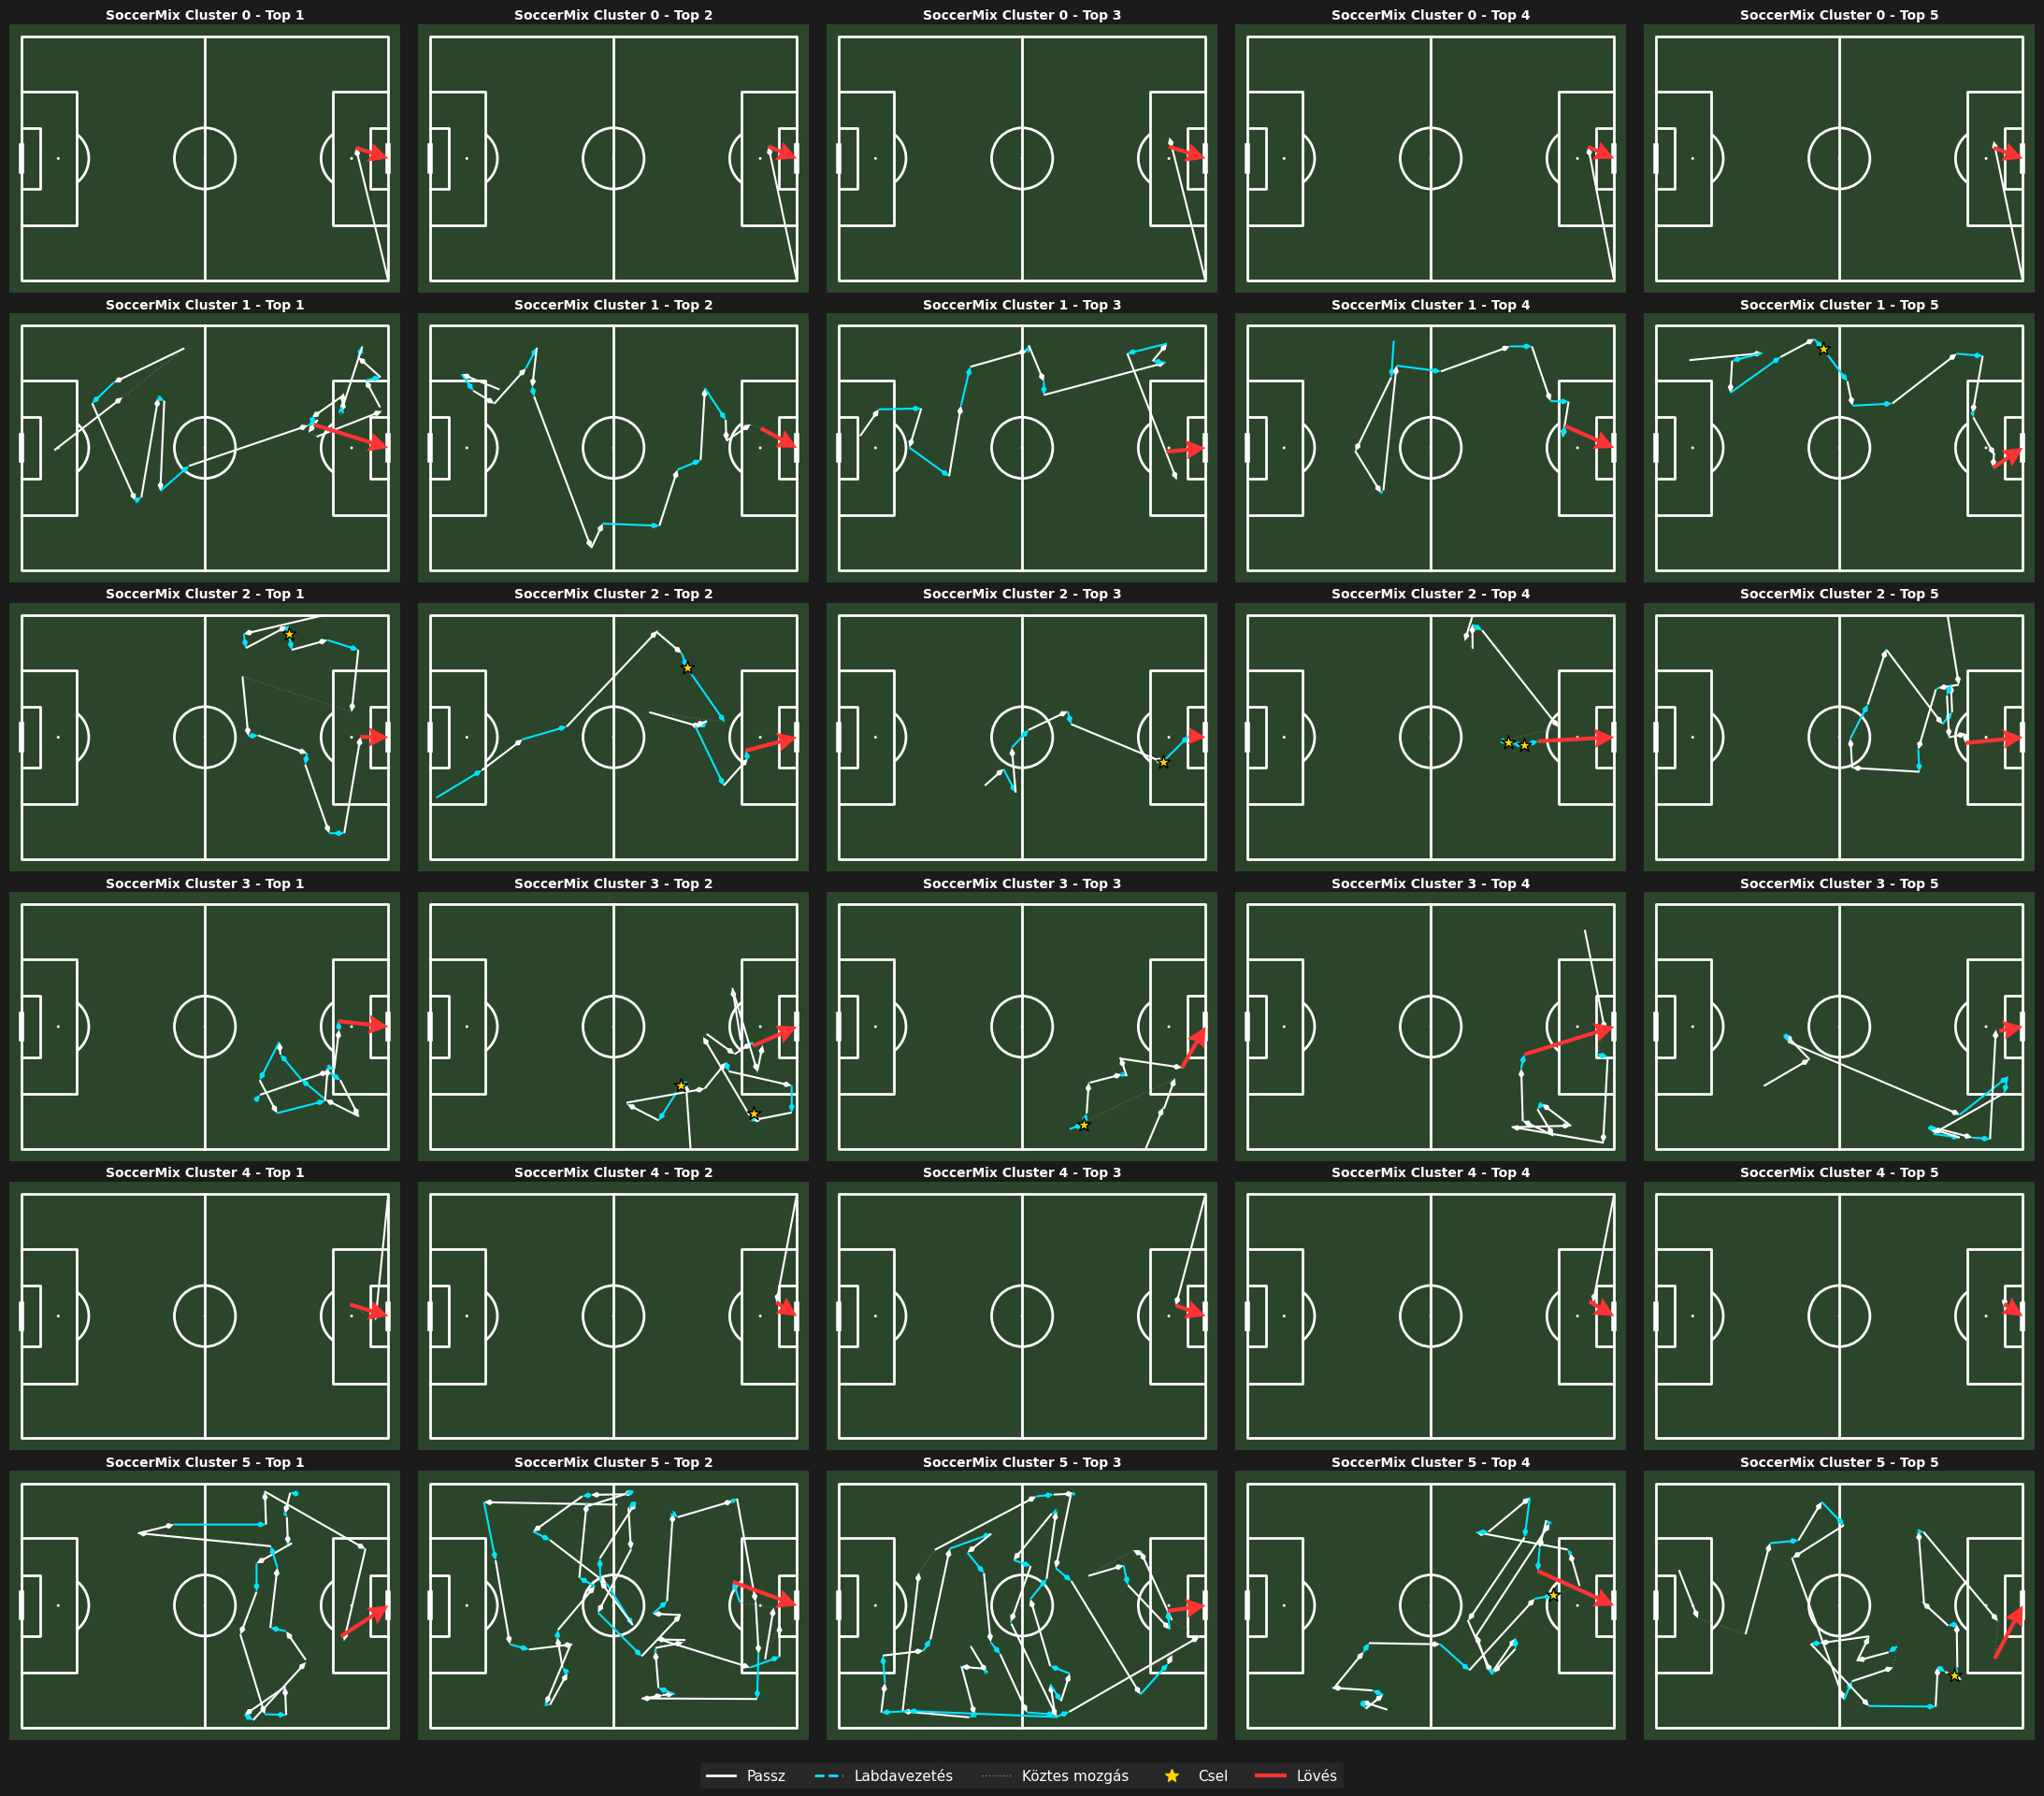

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

try:
    from mplsoccer import Pitch
except ImportError:
    !pip install mplsoccer
    from mplsoccer import Pitch

# 1. Reprezentatív szekvenciák (top 5 / klaszter) kinyerése a PCA-térbeli centroidok alapján
top_n = 5
unique_clusters = sorted(X_soccermix['cluster_soccermix'].unique())
k_clusters = len(unique_clusters)

distances = cdist(X_pca, kmeans.cluster_centers_, metric='euclidean')

# 2. Pályák inicializálása
pitch = Pitch(pitch_type='statsbomb', pitch_color='#2b452b', line_color='white')
fig, axes = pitch.draw(nrows=k_clusters, ncols=top_n, figsize=(22, 3.2 * k_clusters))
fig.patch.set_facecolor('#1b1b1b')

# 3. Klaszterenkénti legközelebbi támadássorozatok kirajzolása
for row_idx, cluster_id in enumerate(unique_clusters):
    cluster_mask = (X_soccermix['cluster_soccermix'] == cluster_id).values
    cluster_indices = np.where(cluster_mask)[0]

    # Adott klaszteren belüli top 5 elem kiválasztása
    top_indices_local = np.argsort(distances[cluster_indices, cluster_id])[:top_n]
    top_seq_ids = X_soccermix.index[cluster_indices[top_indices_local]]

    for sample_idx, seq_id in enumerate(top_seq_ids):
        ax = axes[row_idx, sample_idx] if k_clusters > 1 else axes[sample_idx]
        ax.set_title(f'SoccerMix Cluster {cluster_id} - Top {sample_idx+1}', color='white', fontsize=10, fontweight='bold', pad=4)

        seq_events = df_prepared[df_prepared['sequence_id'] == seq_id].sort_values('index')

        prev_end_x, prev_end_y = None, None
        for _, event in seq_events.iterrows():
            curr_x, curr_y = event['x'], event['y']

            # Koordinátahézagok áthidalása szürke pontozott vonallal
            if prev_end_x is not None and (prev_end_x != curr_x or prev_end_y != curr_y):
                ax.plot([prev_end_x, curr_x], [prev_end_y, curr_y], color='gray', linestyle=':', linewidth=1, alpha=0.5, zorder=2)

            # Passz
            if pd.notna(event.get('pass_end_x')) and pd.notna(event.get('pass_end_y')):
                pitch.arrows(event['x'], event['y'], event['pass_end_x'], event['pass_end_y'], ax=ax, color='white', width=1.5, headwidth=3, headlength=3, zorder=3)
                prev_end_x, prev_end_y = event['pass_end_x'], event['pass_end_y']
            # Labdavezetés
            elif pd.notna(event.get('carry_end_x')) and pd.notna(event.get('carry_end_y')):
                pitch.arrows(event['x'], event['y'], event['carry_end_x'], event['carry_end_y'], ax=ax, color='#00e5ff', width=1.5, headwidth=3, headlength=3, linestyle='--', zorder=3)
                prev_end_x, prev_end_y = event['carry_end_x'], event['carry_end_y']
            else:
                prev_end_x, prev_end_y = curr_x, curr_y

            # Csel
            if event.get('type') == 'Dribble' or event.get('dribble_ratio', 0) > 0:
                ax.scatter(event['x'], event['y'], marker='*', color='gold', s=120, edgecolors='black', zorder=5)
            # Lövés
            if event.get('type') == 'Shot' or pd.notna(event.get('shot_x')):
                shot_x = event.get('shot_x', event['x'])
                shot_y = event.get('shot_y', event['y'])
                pitch.arrows(shot_x, shot_y, 120, 40, ax=ax, color='#ff3333', width=3, headwidth=5, headlength=5, zorder=6)

# 4. Jelmagyarázat
legend_elements = [
    plt.Line2D([0], [0], color='white', lw=2, label='Passz'),
    plt.Line2D([0], [0], color='#00e5ff', lw=2, linestyle='--', label='Labdavezetés'),
    plt.Line2D([0], [0], color='gray', lw=1, linestyle=':', label='Köztes mozgás'),
    plt.Line2D([0], [0], marker='*', color='gold', label='Csel', markerfacecolor='gold', markersize=10, linestyle='None'),
    plt.Line2D([0], [0], color='#ff3333', lw=3, label='Lövés')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=5, fontsize=11, frameon=True, facecolor='#2b2b2b', edgecolor='none', labelcolor='white')

plt.tight_layout()
plt.subplots_adjust(bottom=0.03)
plt.show()

In [121]:
import numpy as np
import pandas as pd

# StatsBomb pálya zónák kategorizálása (120x80)
def get_spatial_zone(x, y):
    # Vertikális harmad (X)
    if x < 40:
        vert = "védekező"
    elif x < 80:
        vert = "középső"
    else:
        vert = "támadó"

    # Horizontális sáv (Y)
    if y < 25 or y > 55:
        horiz = "szél"
    else:
        horiz = "centrális"

    return f"{vert} / {horiz}"

cluster_summary = []

for c in sorted(X_soccermix['cluster_soccermix'].unique()):
    cluster_mask = (X_soccermix['cluster_soccermix'] == c)
    seq_ids = X_soccermix.index[cluster_mask]
    events_c = df_prepared[df_prepared['sequence_id'].isin(seq_ids)]

    # 1. Térbeli zóna és domináns sávok
    start_x = events_c.groupby('sequence_id')['x'].first().mean()
    start_y = events_c.groupby('sequence_id')['y'].first().mean()
    end_x = events_c.groupby('sequence_id')['x'].last().mean()
    end_y = events_c.groupby('sequence_id')['y'].last().mean()

    start_zone = get_spatial_zone(start_x, start_y)
    end_zone = get_spatial_zone(end_x, end_y)

    # 2. Irányvektor és direktség
    delta_x = end_x - start_x
    avg_cos_theta = events_c['cos_theta'].mean()

    # 3. Akcióösszetétel
    pass_pct = (events_c['type'] == 'Pass').mean() * 100
    carry_pct = (events_c['type'] == 'Carry').mean() * 100
    dribble_pct = (events_c['type'] == 'Dribble').mean() * 100

    # 4. Lánchossz és befejezés
    avg_length = events_c.groupby('sequence_id').size().mean()
    shot_ending_pct = events_c.groupby('sequence_id')['type'].apply(lambda s: (s == 'Shot').any()).mean() * 100

    cluster_summary.append({
        'Cluster': c,
        'N': cluster_mask.sum(),
        'Kezdő Zóna': start_zone,
        'ΔX': round(delta_x, 1),
        'cos(θ)': round(avg_cos_theta, 2),
        'Passz %': round(pass_pct, 1),
        'Cipelés %': round(carry_pct, 1),
        'Csel %': round(dribble_pct, 1),
        'Hossz': round(avg_length, 2),
        'Lövés %': round(shot_ending_pct, 1)
    })

profile_df = pd.DataFrame(cluster_summary)
print("=== KLASZTEREK PROFILJA DOMINÁNS ZÓNÁKKAL ===")
print(profile_df.to_string(index=False))

=== KLASZTEREK PROFILJA DOMINÁNS ZÓNÁKKAL ===
 Cluster   N          Kezdő Zóna   ΔX  cos(θ)  Passz %  Cipelés %  Csel %  Hossz  Lövés %
       0 282       támadó / szél -2.1    0.46     47.2        9.0     0.2   2.29    100.0
       1 658 középső / centrális 36.8    0.35     45.2       42.3     2.7  10.22    100.0
       2 310 középső / centrális 27.6    0.54     41.8       35.6     4.6   5.55    100.0
       3 465       támadó / szél 22.2    0.34     45.7       41.0     2.6   9.29    100.0
       4 164       támadó / szél -5.2    0.39     50.4        7.5     0.0   2.37    100.0
       5 811 középső / centrális 49.3    0.26     48.6       44.5     1.9  20.08    100.0


# DTW+KMedoids

In [10]:
!pip install kmedoids

In [ ]:
raw = pd.concat([sb.events(match_id=m) for m in df['match_id'].unique()], ignore_index=True)
df['team'] = df['id'].map(raw.drop_duplicates('id').set_index('id')['team'])

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit, prange
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
import kmedoids

# =====================================================================
# 0) PARAMÉTEREK
# =====================================================================
MAX_LEN   = None        # None = teljes lánc; szám = az utolsó MAX_LEN lépés a lövés előtt
MIN_LEN   = 2           # ennél rövidebb lánc kihagyva (a lövés nélkül számolva)
MIN_CARRY = 3           # StatsBomb-egység; rövidebb carry nem számít lépésnek
MIRROR_Y  = True        # bal-jobb tükrözés
W         = (1.0, 1.0, 0.5, 0.5, 0.5)     # súlyok: x, y, cos, sin, típus
LEN_W     = 0.0         # hosszkülönbség büntetése (0 = nincs); pl. 0.3-mal érdemes próbálni
TYPE_MAP  = {'Pass': 1.0, 'Carry': 0.0, 'Dribble': 0.0}
SEED      = 0

# =====================================================================
# 1) LÉPÉSEK (a lövés nélkül); irány = egységvektor kezdő- és végpont között
# =====================================================================
d = df.sort_values(['sequence_id', 'index']).copy()
d = d[d['type'].isin(list(TYPE_MAP) + ['Shot'])].copy()

d['end_x'] = d['pass_end_x'].fillna(d['carry_end_x'])
d['end_y'] = d['pass_end_y'].fillna(d['carry_end_y'])
g = d.groupby('sequence_id')
d['end_x'] = d['end_x'].fillna(g['x'].shift(-1))        # Dribble: a következő lépés kezdőpontja
d['end_y'] = d['end_y'].fillna(g['y'].shift(-1))

d = d[d['type'] != 'Shot'].copy()                        # a lövést kihagyjuk (az irány már megvan)

clen = np.hypot(d['end_x'] - d['x'], d['end_y'] - d['y'])
d = d[~((d['type'] == 'Carry') & (clen < MIN_CARRY))].copy()

dx, dy = d['end_x'] - d['x'], d['end_y'] - d['y']
nrm = np.hypot(dx, dy)
ok = np.isfinite(nrm) & (nrm > 1e-6)
d['cos'] = np.where(ok, dx / nrm, 0.0)
d['sin'] = np.where(ok, dy / nrm, 0.0)
d['typ'] = d['type'].map(TYPE_MAP)
print("lépések:", len(d), "| irány nélküli lépések aránya:", round(1 - ok.mean(), 3))

# =====================================================================
# 2) LÁNCOK: (x/120, y/80, cos, sin, típus) lépésenként
# =====================================================================
rows = []
for sid, g in d.groupby('sequence_id', sort=False):
    if MAX_LEN:
        g = g.tail(MAX_LEN)
    if len(g) < MIN_LEN or g[['x', 'y']].isna().any().any():
        continue
    X, Y = g['x'].to_numpy(), g['y'].to_numpy()
    C, S_ = g['cos'].to_numpy().copy(), g['sin'].to_numpy().copy()
    if MIRROR_Y and (Y - 40).sum() > 0:                  # a lánc átlagos oldala alapján
        Y, S_ = 80 - Y, -S_                              # tükrözésnél a sin előjele is fordul
    rows.append(dict(sequence_id=sid, match_id=g['match_id'].iloc[0], year=g['year'].iloc[0],
                     n=len(g), base=np.c_[X / 120, Y / 80, C, S_, g['typ'].to_numpy()]))

chains = pd.DataFrame(rows).reset_index(drop=True)
n = len(chains)
L = chains['n'].to_numpy(np.int64)
maxlen = int(L.max())
print(f"{n} lánc | lánchossz: medián {np.median(L):.0f}, 90. percentilis {np.percentile(L, 90):.0f}, max {maxlen}")

BASE = np.zeros((n, maxlen, 5))
for i, (b, l) in enumerate(zip(chains['base'], L)):
    BASE[i, :l] = b

def make_P(Wt):
    return np.ascontiguousarray(BASE * np.asarray(Wt, dtype=float))
P = make_P(W)

# =====================================================================
# 3) DTW (normalizált, tetszőleges számú jellemzőre, változó hosszra)
# =====================================================================
@njit(cache=True)
def _dtw(a, la, b, lb, len_w):
    D = np.full((la + 1, lb + 1), 1e18)
    D[0, 0] = 0.0
    for i in range(1, la + 1):
        for j in range(1, lb + 1):
            s = 0.0
            for k in range(a.shape[1]):
                diff = a[i-1, k] - b[j-1, k]
                s += diff * diff
            D[i, j] = np.sqrt(s) + min(D[i-1, j], D[i, j-1], D[i-1, j-1])
    out = D[la, lb] / (la + lb)                          # hossznormalizálás
    out += len_w * abs(la - lb) / max(la, lb)            # opcionális hosszbüntetés
    return out

@njit(parallel=True, cache=True)
def dtw_matrix(P, L, len_w):
    n = P.shape[0]
    M = np.zeros((n, n), dtype=np.float64)
    for i in prange(n):
        for j in range(i + 1, n):
            v = _dtw(P[i], L[i], P[j], L[j], len_w)
            M[i, j] = v
            M[j, i] = v
    return M

D = dtw_matrix(P, L, LEN_W)
print("DTW mátrix:", D.shape)

lépések: 22088 | irány nélküli lépések aránya: 0.024
2124 lánc | lánchossz: medián 8, 90. percentilis 21, max 94
DTW mátrix: (2124, 2124)


     k     loss  silhouette
0    3  720.182       0.150
1    4  696.163       0.108
2    5  678.342       0.104
3    6  661.423       0.079
4    7  646.278       0.082
5    8  635.410       0.072
6    9  625.862       0.077
7   10  618.097       0.072
8   11  611.941       0.070
9   12  605.919       0.069
10  13  600.569       0.062
11  14  594.792       0.063
12  15  589.087       0.060
13  16  585.615       0.062
14  17  581.852       0.059
15  18  576.871       0.055
16  19  573.323       0.051
17  20  570.269       0.051


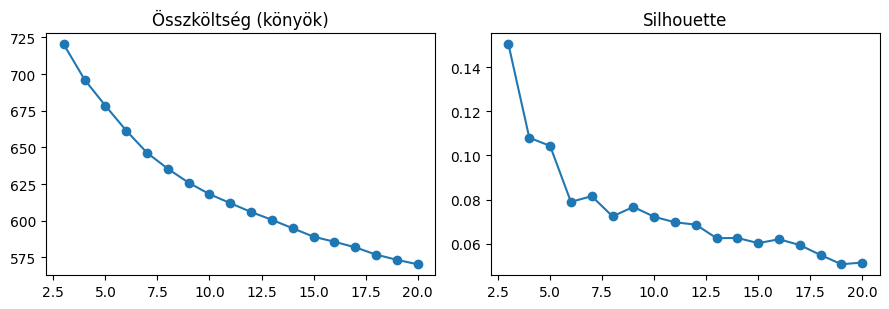

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kmedoids
from sklearn.metrics import silhouette_score

# =====================================================================
# 1) k KIVÁLASZTÁSA: összköltség (könyök) + silhouette
# =====================================================================
rows = []
for k in range(3, 21):
    sol = kmedoids.fasterpam(D, k, max_iter=100, random_state=0)
    sil = silhouette_score(D, sol.labels, metric='precomputed')
    rows.append((k, sol.loss, sil))
sel = pd.DataFrame(rows, columns=['k', 'loss', 'silhouette'])
print(sel.round(3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(sel.k, sel.loss, 'o-');       ax[0].set_title('Összköltség (könyök)')
ax[1].plot(sel.k, sel.silhouette, 'o-'); ax[1].set_title('Silhouette')
plt.tight_layout(); plt.show()



cluster
0    460
1    304
2    395
3    479
4    486
Name: count, dtype: int64


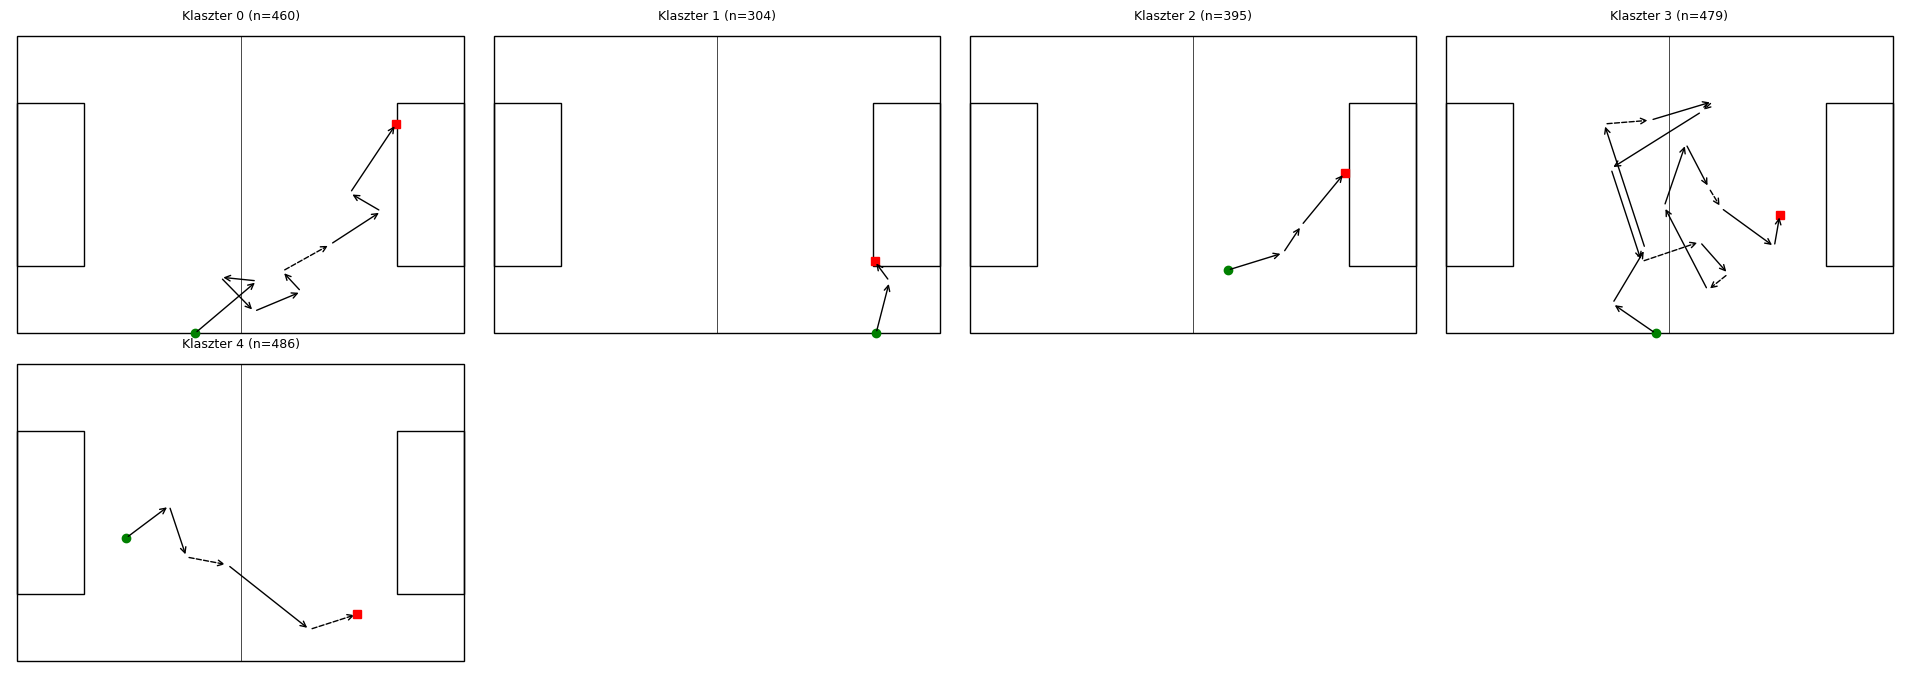

In [40]:
# =====================================================================
# 2) VÉGLEGES KLASZTEREZÉS
# =====================================================================
K = 5                                                      # a fenti görbék és a 3. lépés alapján
best = min((kmedoids.fasterpam(D, K, max_iter=200, random_state=r) for r in range(10)),
           key=lambda s: s.loss)                           # 10 újraindításból a legjobb
med, labels = best.medoids, best.labels
chains['cluster'] = labels
print(chains['cluster'].value_counts().sort_index())

# =====================================================================
# 3) MEDOID-LÁNCOK ÁBRÁZOLÁSA
# =====================================================================
def draw_pitch(ax):
    ax.add_patch(plt.Rectangle((0, 0), 120, 80, fill=False))
    ax.plot([60, 60], [0, 80], 'k-', lw=0.5)
    ax.add_patch(plt.Rectangle((102, 18), 18, 44, fill=False))
    ax.add_patch(plt.Rectangle((0, 18), 18, 44, fill=False))
    ax.set_xlim(-2, 122); ax.set_ylim(-2, 82); ax.set_aspect('equal'); ax.axis('off')

cols = 4
nr = int(np.ceil(K / cols))
fig, axes = plt.subplots(nr, cols, figsize=(4.8 * cols, 3.4 * nr))
for c, ax in zip(range(K), axes.ravel()):
    draw_pitch(ax)
    m, l = med[c], L[med[c]]
    xy = BASE[m, :l, :2] * [120, 80]                       # vissza a StatsBomb-koordinátákra
    typ = BASE[m, :l, 4]
    for i in range(l - 1):
        ax.annotate('', xy=xy[i + 1], xytext=xy[i],
                    arrowprops=dict(arrowstyle='->', ls='-' if typ[i] == 1 else '--'))
    ax.plot(*xy[0], 'go'); ax.plot(*xy[-1], 'rs')          # zöld = kezdet, piros = vég
    ax.set_title(f"Klaszter {c} (n={(labels == c).sum()})", fontsize=9)
for ax in axes.ravel()[K:]:
    ax.axis('off')
plt.tight_layout(); plt.show()